In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import cm, colors

import glob
import gc
import warnings
import copy
import pathlib
import pickle

import os

from scipy import stats
import signac
import freud
import gsd.hoomd
import omd
import schmeud
import schmeud._schmeud as schmeud_rs
from schmeud._schmeud import statics
from schmeud import ml

from dataclasses import dataclass
from collections import defaultdict

from numba import njit

from tqdm.notebook import tqdm

In [2]:
from monk import nb, prep, pair, render, utils, workflow, grid, prep as prep_mod

parent = pathlib.Path(os.getcwd()).parent.parent / "config.yaml"
config = workflow.get_config(parent.as_posix())
parent, config

(PosixPath('/home/ian/Projects/work/monk/workflows/2d-osc-shear/config.yaml'),
 {'root': '/media/ian/Data2/monk/2d-osc-shear',
  'origin': '/media/ian/Data2/monk/2d-esl'})

In [3]:
project: signac.Project = signac.get_project(root=config['root'])
project.doc

{'avail_seed': 18, 'dt': 0.005, 'step_unit': 200, 'equil_time': 100, 'min_periods': 20, 'dumps': 40, 'period_times': [30.0, 100.0, 300.0, 1000.0], 'max_shears': [0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.04, 0.06, 0.07], '_status': {}}

In [4]:
class InteractionComputer:

    def _setup_nve_sim(self, pot, dt=0.01):
        if isinstance(pot, str):
            pot = [pot]
        elif isinstance(pot, list):
            pass
        else:
            raise ValueError("The 'potential' must be a string or list")ygjgygg

        nvt = hoomd.md.methods.NVE(hoomd.filter.All())
        integrator.forces = [force]
        integrator.methods = [nvt]

        self._sim.operations.integrator = integrator

        self._nlist = tree

        return nvt

    def __init__(self, filename, pot, frame=0, device=None, seed=None):
        if device is None:
            device = hoomd.device.CPU()
        sim = hoomd.Simulation(device, seed=seed)
        sim.create_state_from_gsd(filename, frame=frame)
        self._sim = sim
        self._file_handle = gsd.hoomd.open(name=filename, mode='rb')

        self._setup_nve_sim(pot)

        self._sim.always_compute_pressure = True

        self._snap = None

        sim.run(0)

    def get_energy(self):
        assert len(self._sim.operations.integrator.forces) == 1
        self._sim.run(0)
        return self._sim.operations.integrator.forces[0].energy

    def get_forces(self):
        assert len(self._sim.operations.integrator.forces) == 1
        self._sim.run(0)
        return self._sim.operations.integrator.forces[0].forces
    
    def get_virials(self):
        assert len(self._sim.operations.integrator.forces) == 1
        self._sim.run(0)
        return self._sim.operations.integrator.forces[0].virials
    
    def get_pairs(self):
        self._sim.run(0)
        return self._nlist.pair_list()
    
    def get_snapshot(self):
        if self._snap is None or self._sim.timestep != self._snap.configuration.step:
            self._snap = self._sim.state.get_snapshot()
        return self._snap

    def get_positions(self):
        snap = self.get_snapshot()
        return snap.positions
    
    def get_box(self):
        return self._sim.state.box

    def set_frame(self, frame):
        snap = self._file_handle[frame]
        snap = hoomd.Snapshot.from_gsd_snapshot(snap, hoomd.communicator.Communicator())
        self._sim.state.set_snapshot(snap)

    def set_file(self, filename, frame=0):
        self._file_handle = gsd.hoomd.open(name=filename, mode='rb')
        self.set_frame(frame)

In [5]:
@dataclass(frozen=True, eq=True)
class Statepoint:
    max_shear: float
    period: float
    temp: float
    prep: str

In [25]:
output = defaultdict(list)

postfix = {"cycle": 0}
pbar = tqdm(total=len(list(project.find_jobs())))

for job in project:
    print(job)
    prep = job.sp["prep"]
    # if prep == "HTL":
    #     continue
    
    experiments = sorted(glob.glob(job.fn("aqs_linear_experiments/*0.40/*/traj_period-*.gsd")))
    inter_computer = InteractionComputer(experiments[0], job.sp["pot"], frame=0)

    for exper in experiments:
        max_shear = utils.extract_between(exper, "max-shear-", "/")
        period = utils.extract_between(exper, "period-", "_")
        temp = utils.extract_between(exper, "temp-", "/")
        df_path = f"aqs_linear_experiments/max-shear-{max_shear}/temp-{temp}/energy-strob_period-{period}.parquet"
        sp = Statepoint(max_shear=float(max_shear), period=float(period), temp=float(temp), prep=prep)
        
        # if float(period) != 1000.0:
        #     continue

        traj = gsd.hoomd.open(exper)

        energies = []
        shear = []
        stresses = []

        if job.isfile(df_path):
            dataset = pd.read_parquet(job.fn(df_path))
            output[sp].append(dataset)
            continue

        for i in range(len(traj)):
            postfix["cycle"] = i
            inter_computer.set_file(exper, frame=i)

            snap = traj[i] # initial state
            # print(snap.log)
            xy = snap.configuration.box[3]
            energy = inter_computer.get_energy()
            stress = np.mean(inter_computer.get_virials()[:, 1])
            postfix["xy"] = xy
            postfix["energy"] = energy
            postfix["stress"] = stress
            # energy = snap.log["md/compute/ThermodynamicQuantities/energy"][0]

            energies.append(energy)
            shear.append(xy)
            stresses.append(stress)
            pbar.set_postfix(postfix)
            # print(energy)
            # break
        # break
        dataset = pd.DataFrame({"energy": energies, "shear": shear, "stress": stresses})
        dataset.to_parquet(job.fn(df_path))
        output[sp].append(dataset)
    # break
    pbar.update(1)

# with open(project.fn("results/longer-energy-aqs_period-1000.pkl"), "wb") as f:
#     pickle.dump(output, f)

  0%|          | 0/12 [00:00<?, ?it/s]

634e14bc75836df75158fb15f379d8bb
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
7ec2f6aca035e69077eab24383a21cb6
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
cfa1e4c0007fd65d020f809715a6f0b4
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
ecce68c50e28a33684826f28780bf6e9
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
1d0fe2ba44a6f635f5504dcbcee0ebc9
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
1083a2a09eec2c6cf215ebc7a9706cac
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
09d3dccc56f1fa9330b57901cd232ab7
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
6976a7c10ada4159010403f8027f3ea5
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
9158e73b2e4c9fd1a565e1e5d1bc3af5
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
c6d7afd0de62bfa16d05da47815227eb
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
bf92a185d043ce3ef666e05e427c7e76
Using pair function:  <function KA_LJ at 0x7ba1d61392d0>
a8f2c249ed

0.0
0.0


Text(0.5, 0, '$\\gamma$')

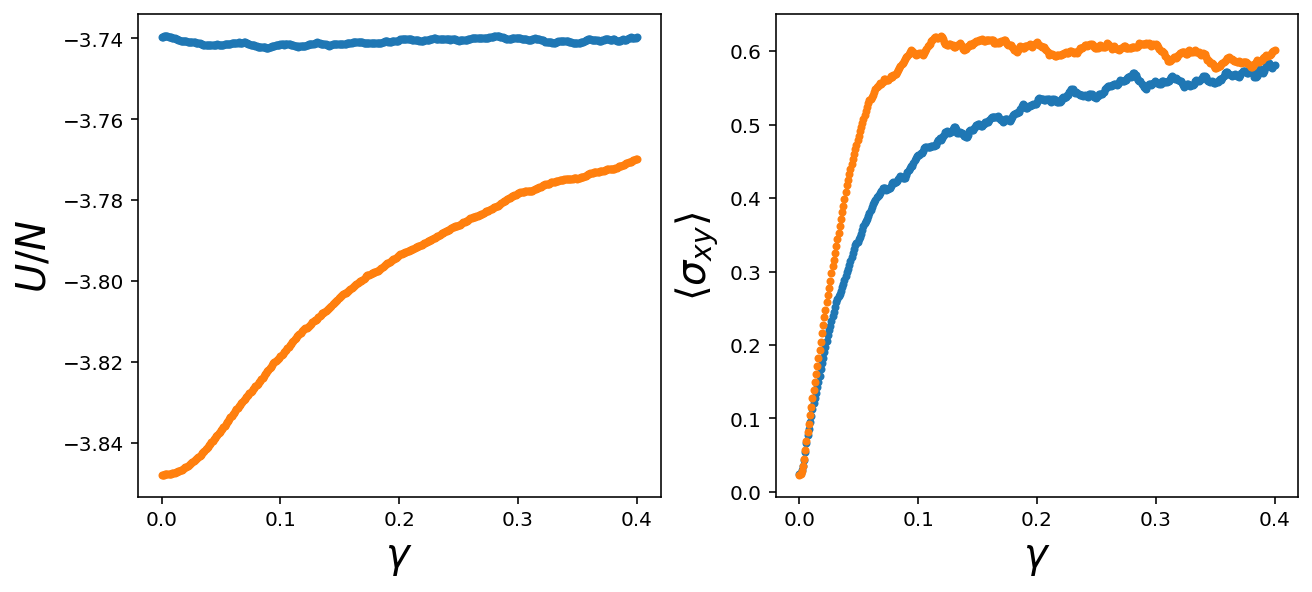

In [40]:
# @dataclass(frozen=True, eq=True)
# class Plot:
#     period: float
#     temp: float
#     prep: str

from scipy.ndimage import uniform_filter1d
# plot = defaultdict(list)

fig, axs = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")

for key, value in output.items():
    # if key.temp < 1e-2 or key.temp < 2e-2:
    #     continue
    print(key.temp)
    if key.temp != 0.0: # or key.prep != "ESL" or key.max_shear > 0.06:
        continue
    # pt = Plot(period=key.period, temp=key.temp, prep=key.prep)
    # plot.append()
    # energy = value[0]["energy"].values[-1]
    xy = value[0]["shear"].values
    energy = np.mean([v["energy"].values for v in value], axis=0)/2**15
    stress = -np.mean([v["stress"].values for v in value], axis=0)
    energy = uniform_filter1d(energy, size=10)
    stress = uniform_filter1d(stress, size=10)
    
    # plt.plot(energy)
    axs[0].plot(xy, energy, ".")
    # print(key, len(value))
    axs[1].plot(xy, stress, ".")

axs[1].set_ylabel(r"$\langle \sigma_{xy} \rangle$", size=20)
axs[1].set_xlabel(r"$ \gamma $", size=20)
axs[0].set_ylabel(r"$U/N$", size=20)
axs[0].set_xlabel(r"$\gamma$", size=20)
# axs[1].set_xscale('log')
# axs[1].set_yscale('log')

In [33]:
2**15

32768

In [12]:
len(output.keys())

18

In [34]:
def plot_stress_strain(shear, axs=None, legend=True):
    if axs is None:
        fig, axs = plt.subplots(1, 6, figsize=(24, 4))
    else:
        fig = axs.figure
    
    cmap = cm.inferno
    norm = colors.Normalize(vmin=0, vmax=.3)

    for k, v in output.items():
        if k.max_shear != shear:
            continue
        # print(k)
        c = cmap(norm(k.temp))
        if k.prep == "ESL":
            ls = "--"
        else:
            ls = "-"

        # temp to idx mapping using
        temps = [0.0019836, 0.019836, 0.049591, 0.099182, 0.14877, 0.19836]
        i = temps.index(k.temp)
        # if i == 5:
        #     continue

        # stress = np.mean([v_i["stress"].values for v_i in v], axis=0)[-40*50-1:]
        # strain = np.mean([v_i["strain"].values for v_i in v], axis=0)[-40*50-1:]
        stress = np.mean([v_i["stress"].values for v_i in v], axis=0)[:40*10-1]
        strain = np.mean([v_i["strain"].values for v_i in v], axis=0)[:40*10-1]
        stress = np.array([np.mean(stress[i::40]) for i in range(41)])
        strain = np.array([np.mean(strain[i::40]) for i in range(41)])
        # print(k, stress.shape, strain.shape)
        # frames = v[0]["frame"].values
        axs[i].plot(strain, stress, color=c, linestyle=ls, label=f"{k.temp:.3f} {k.prep}", alpha=1)
    for ax in axs:
        ax.set_ylabel("Stress", size="large")
        ax.set_xlabel("Strain", size="large")
        if legend:
            ax.legend(title="Temp Prep")
    fig.suptitle(f"Stress-strain; {shear} shear, 1000 period")

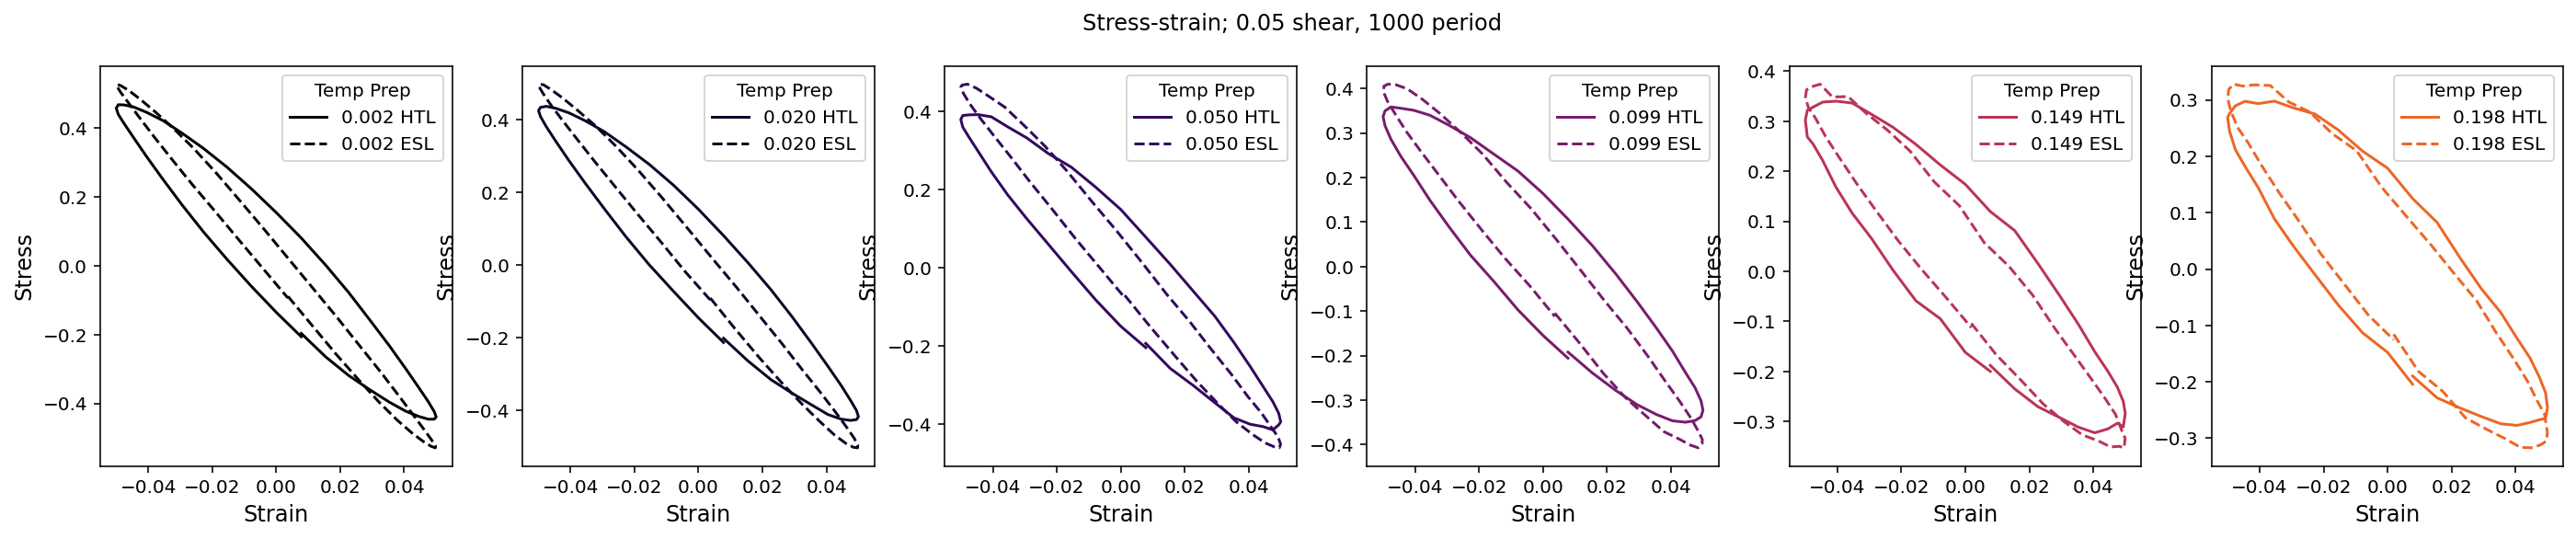

In [35]:
plot_stress_strain(0.05, legend=True)

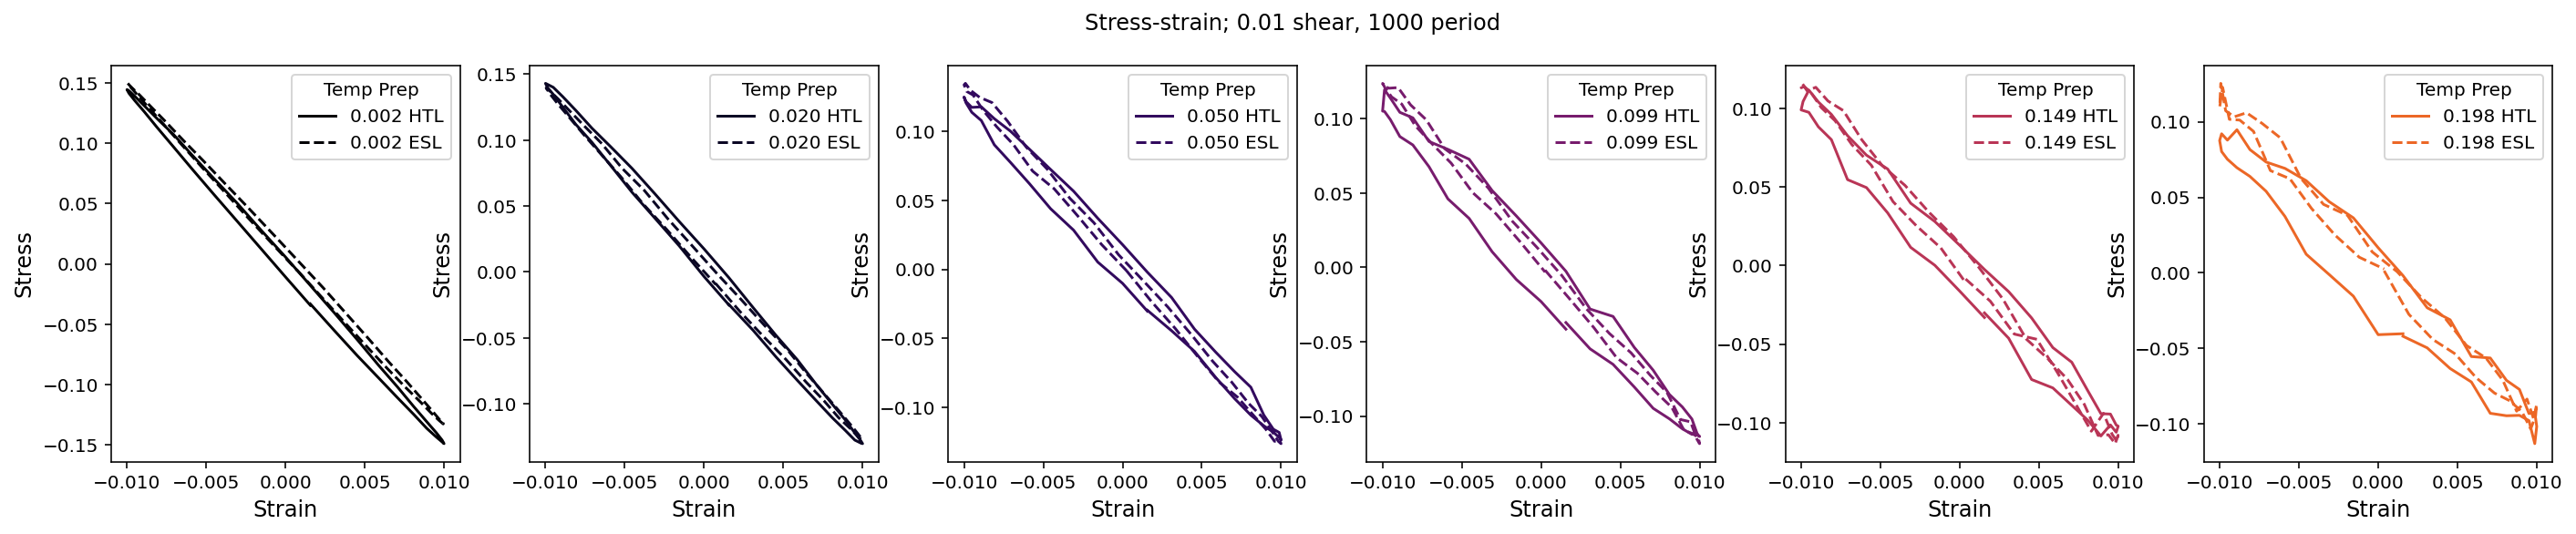

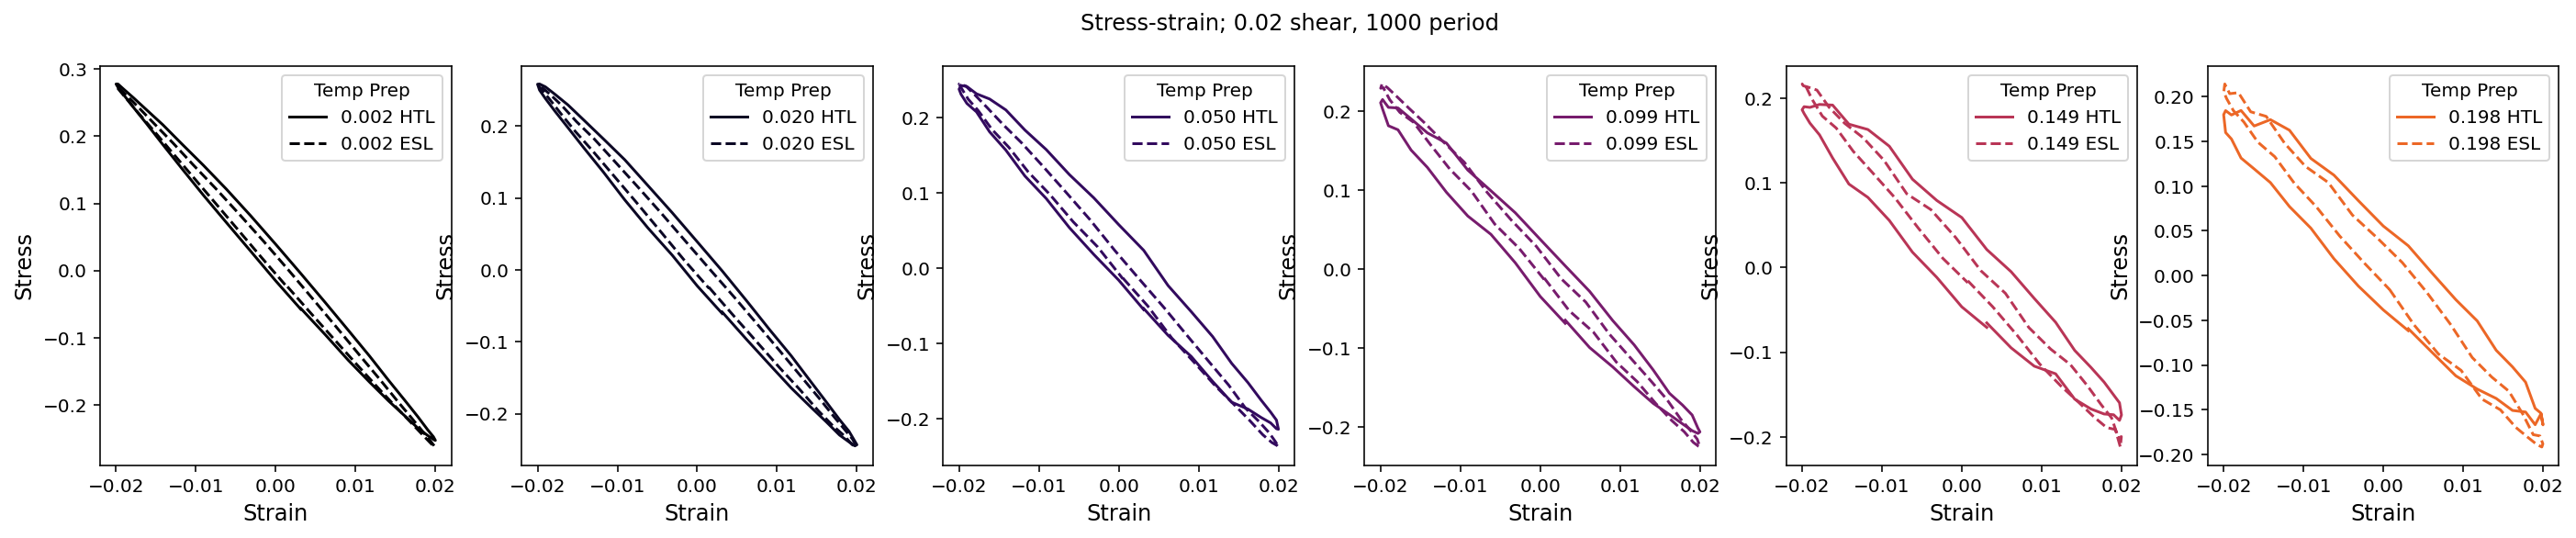

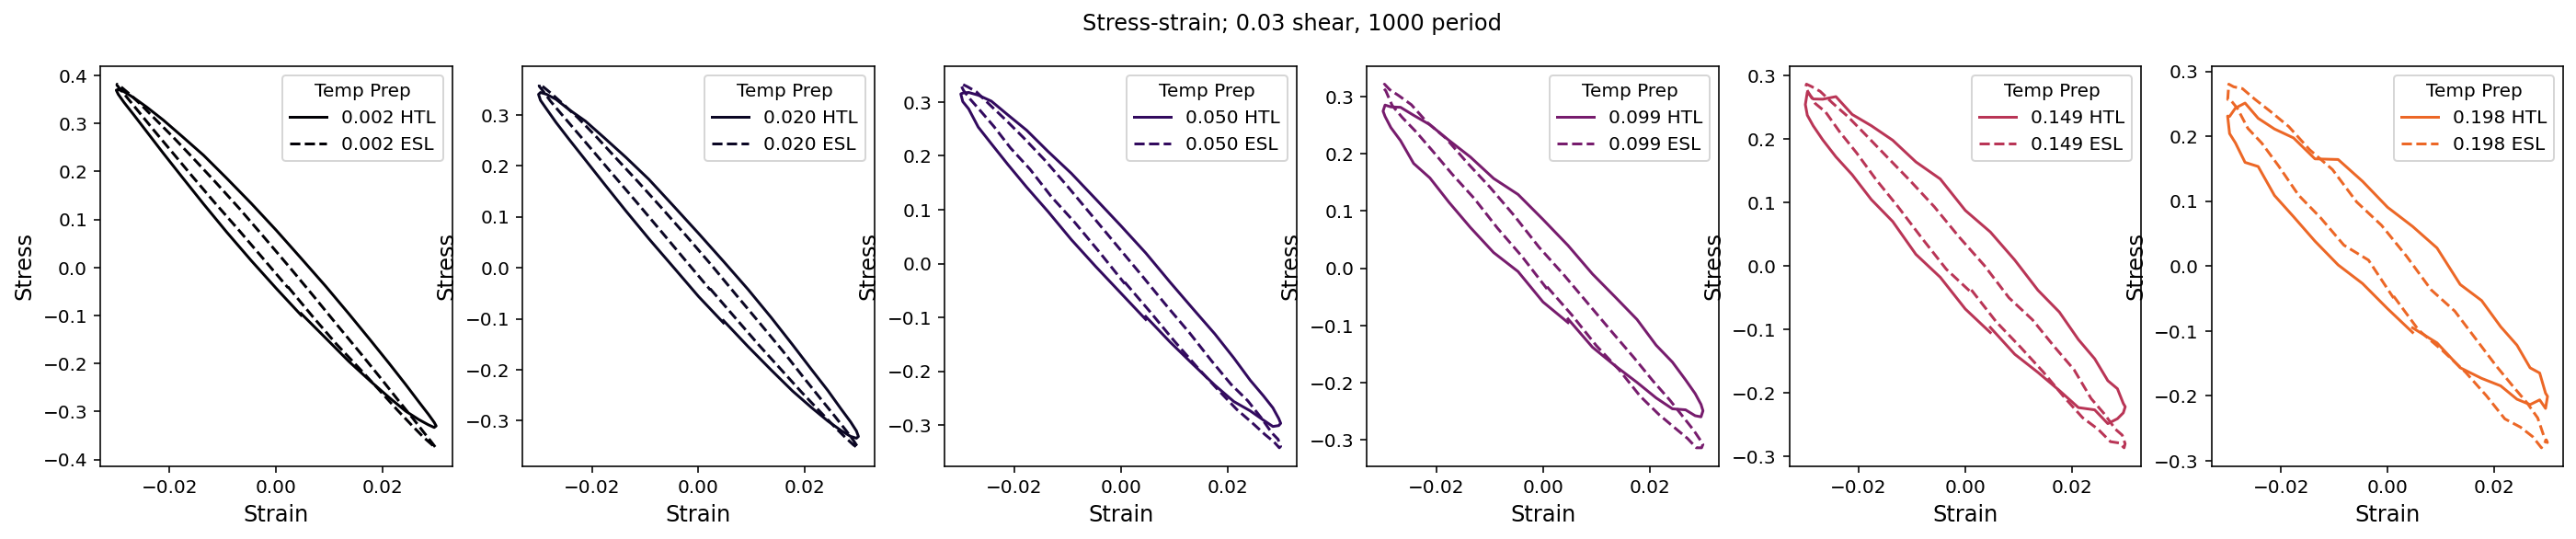

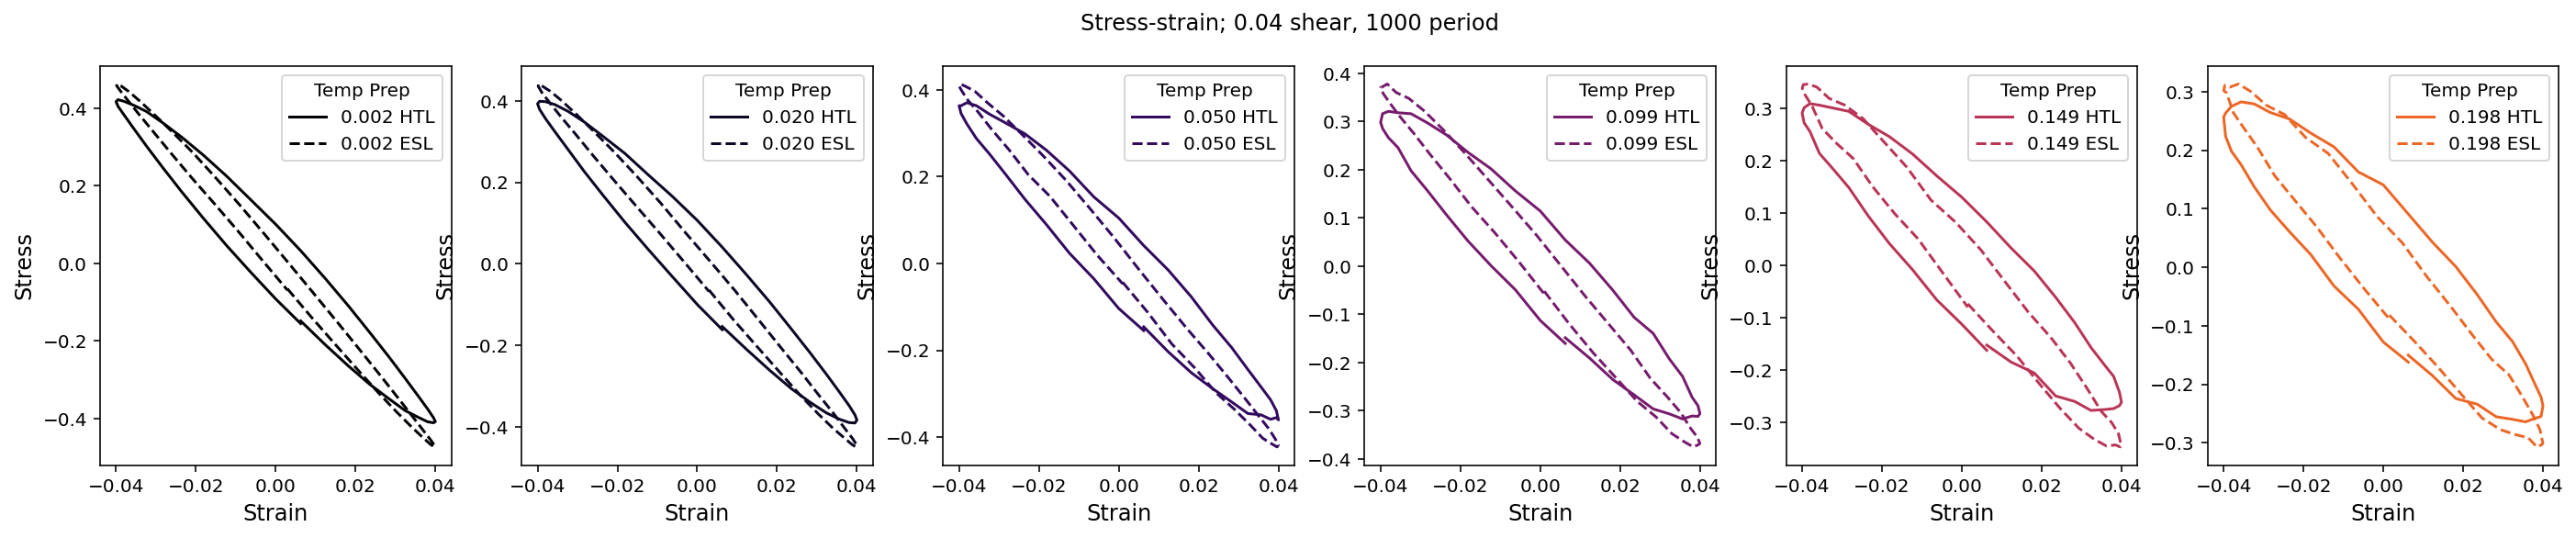

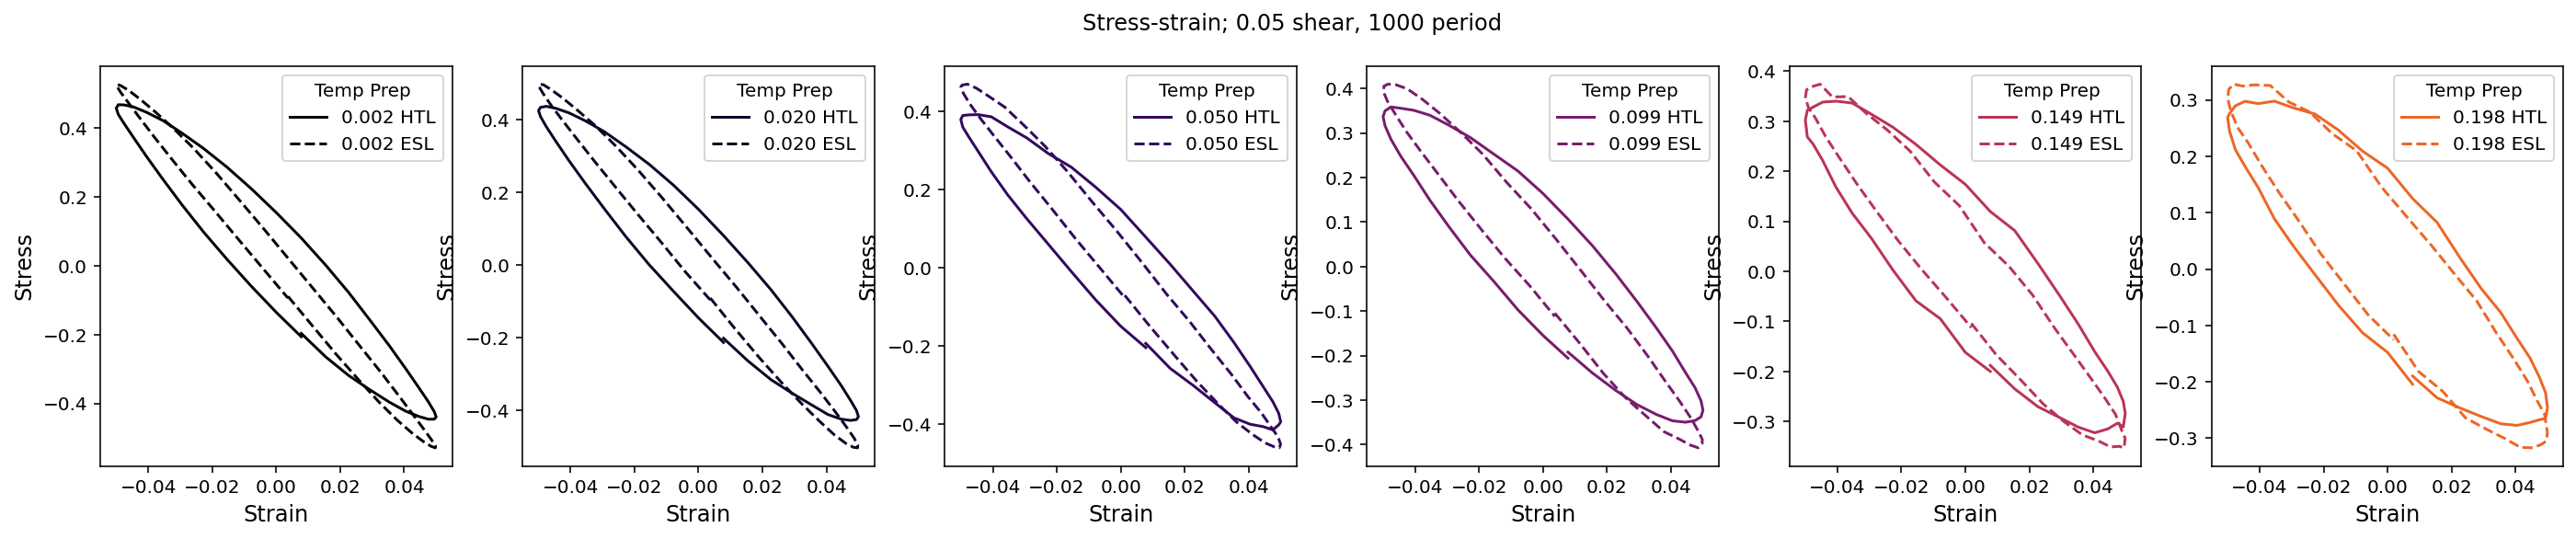

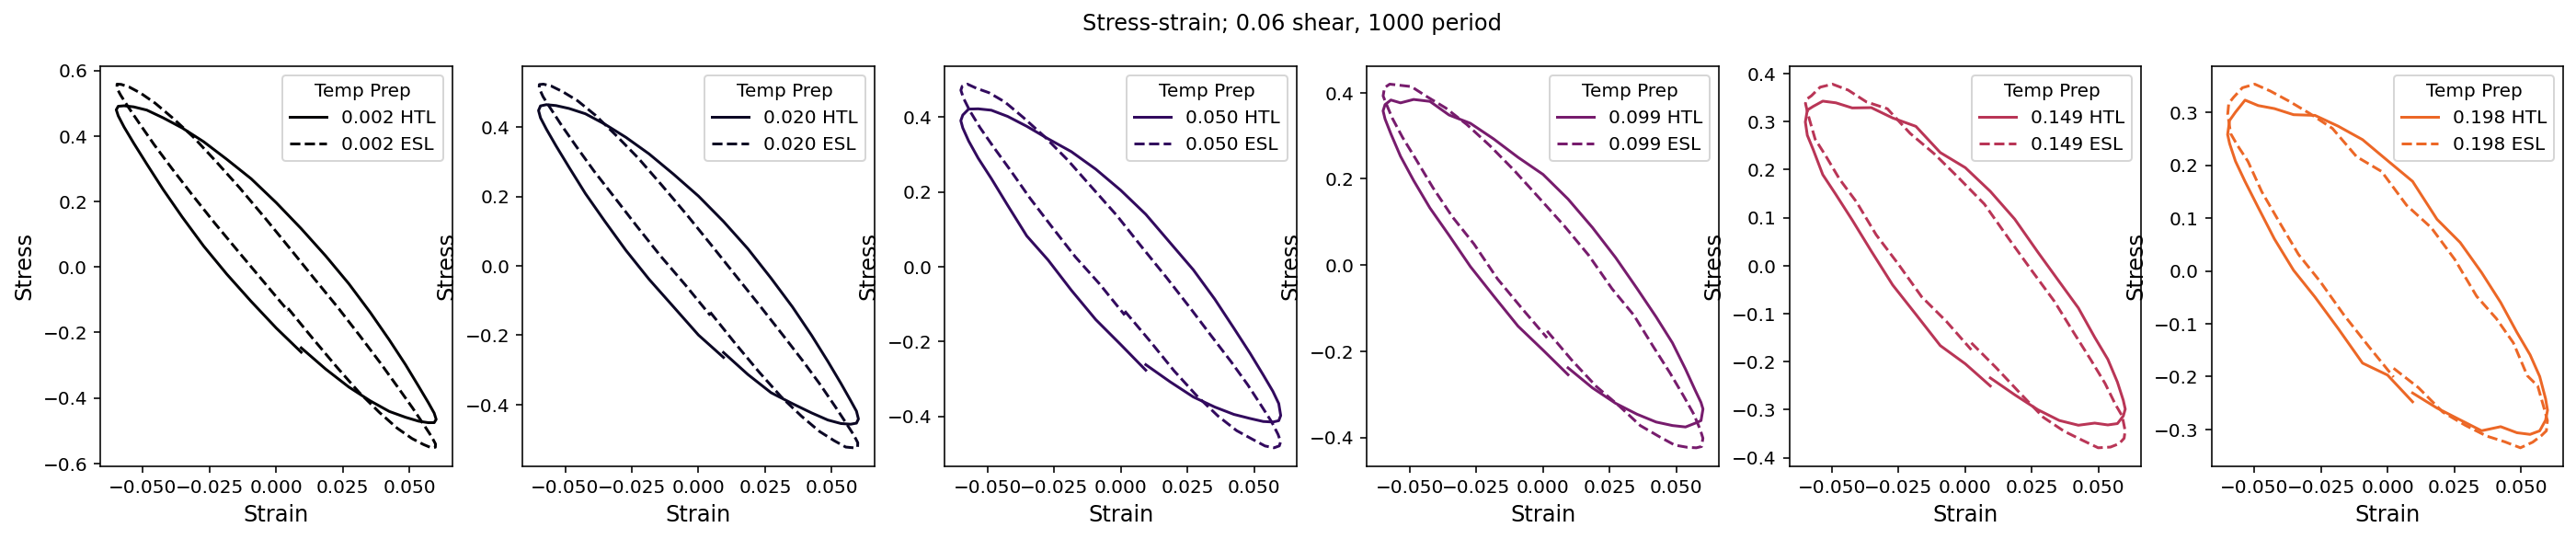

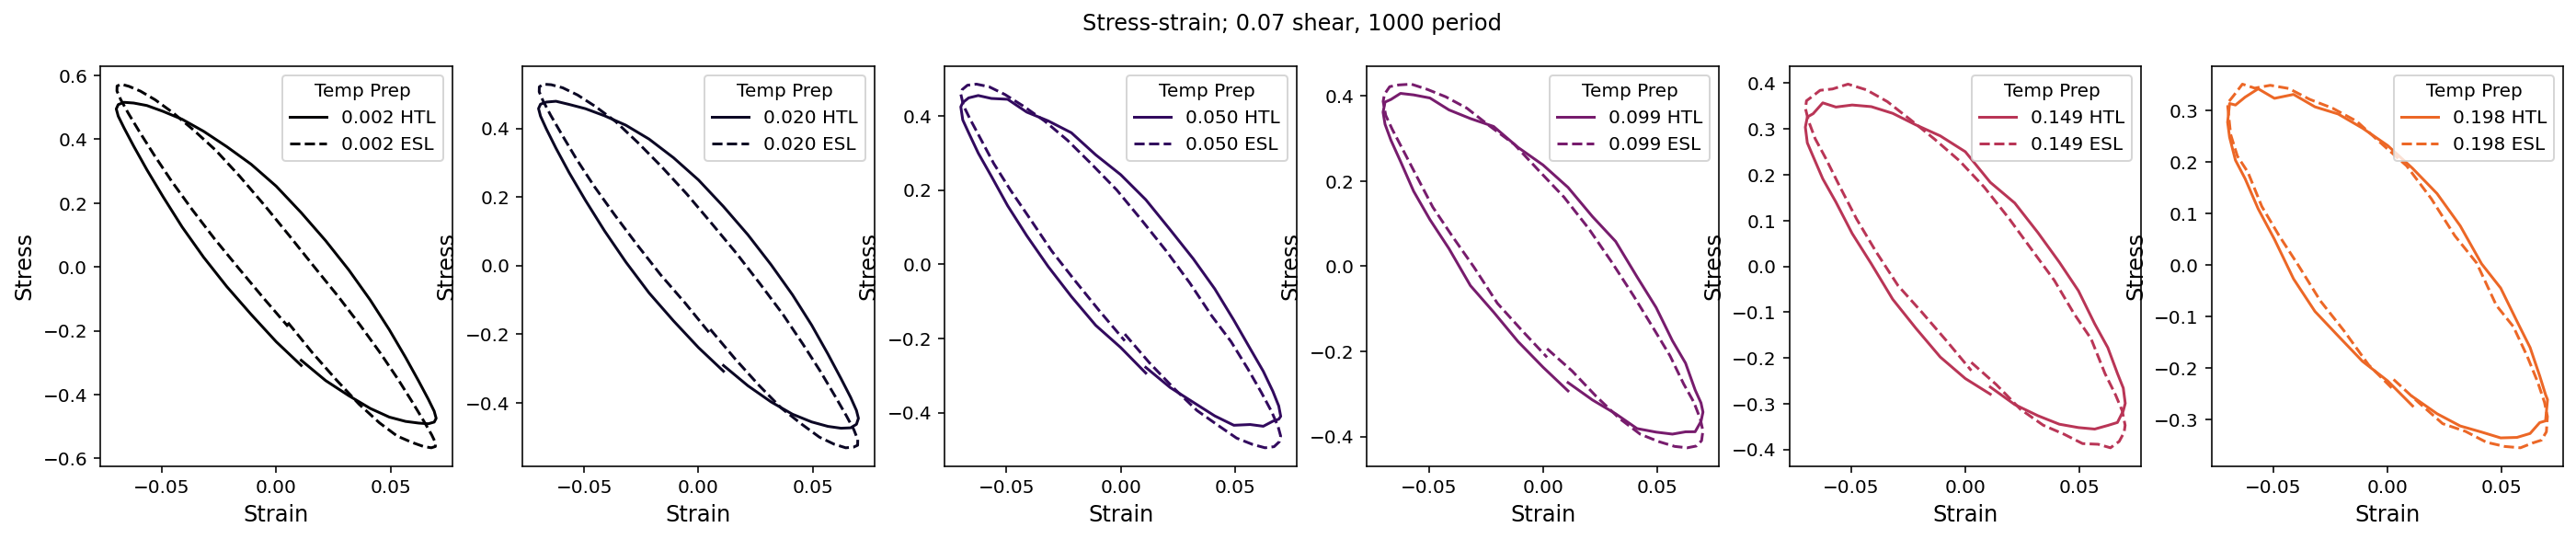

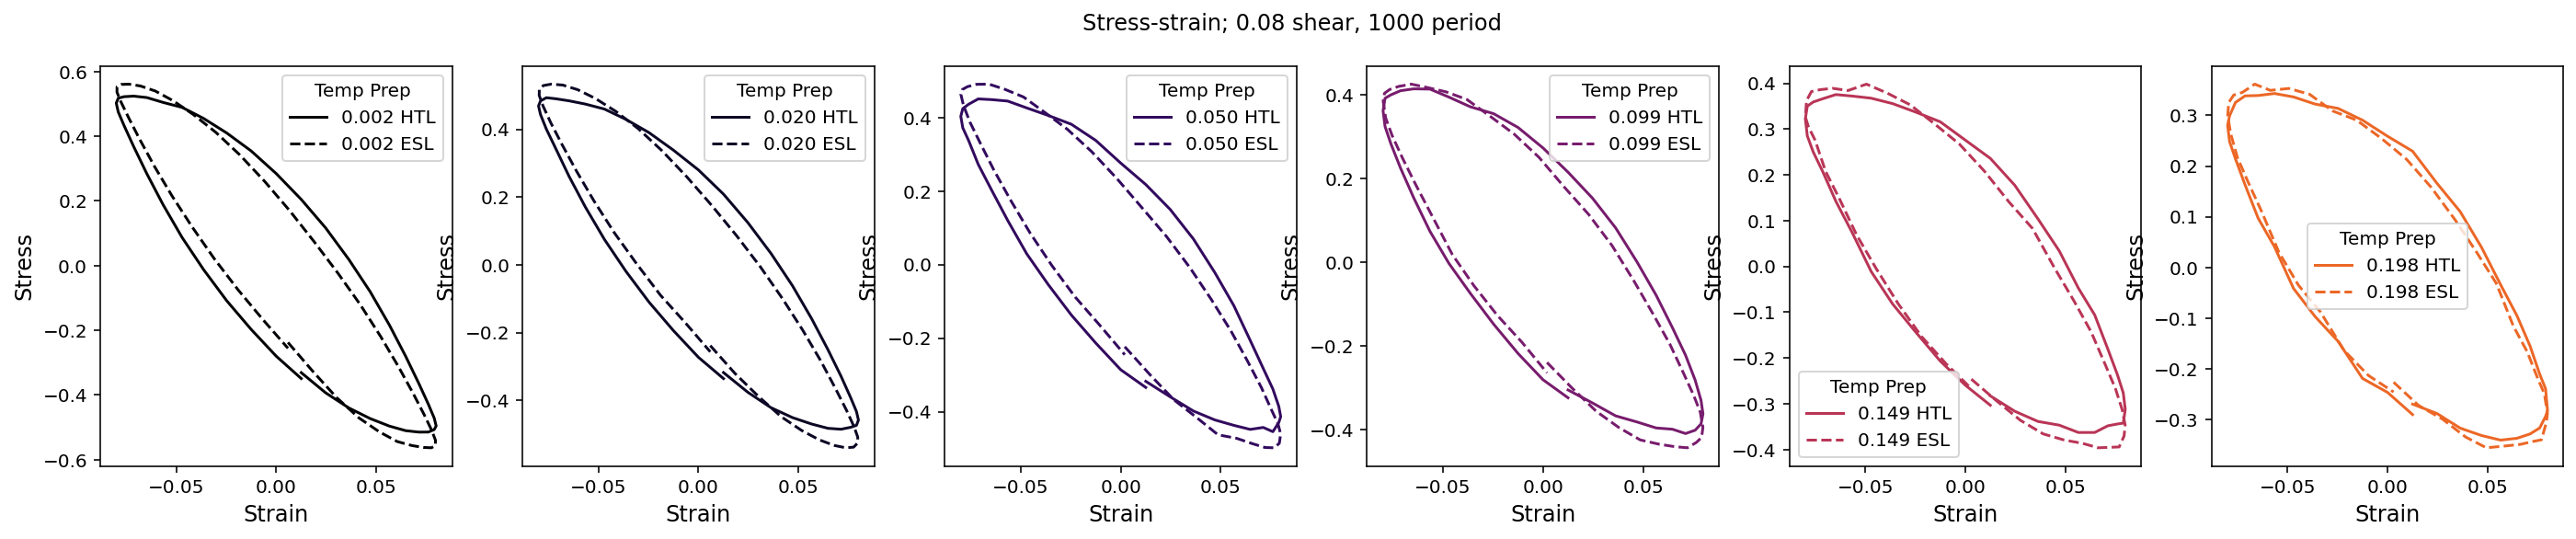

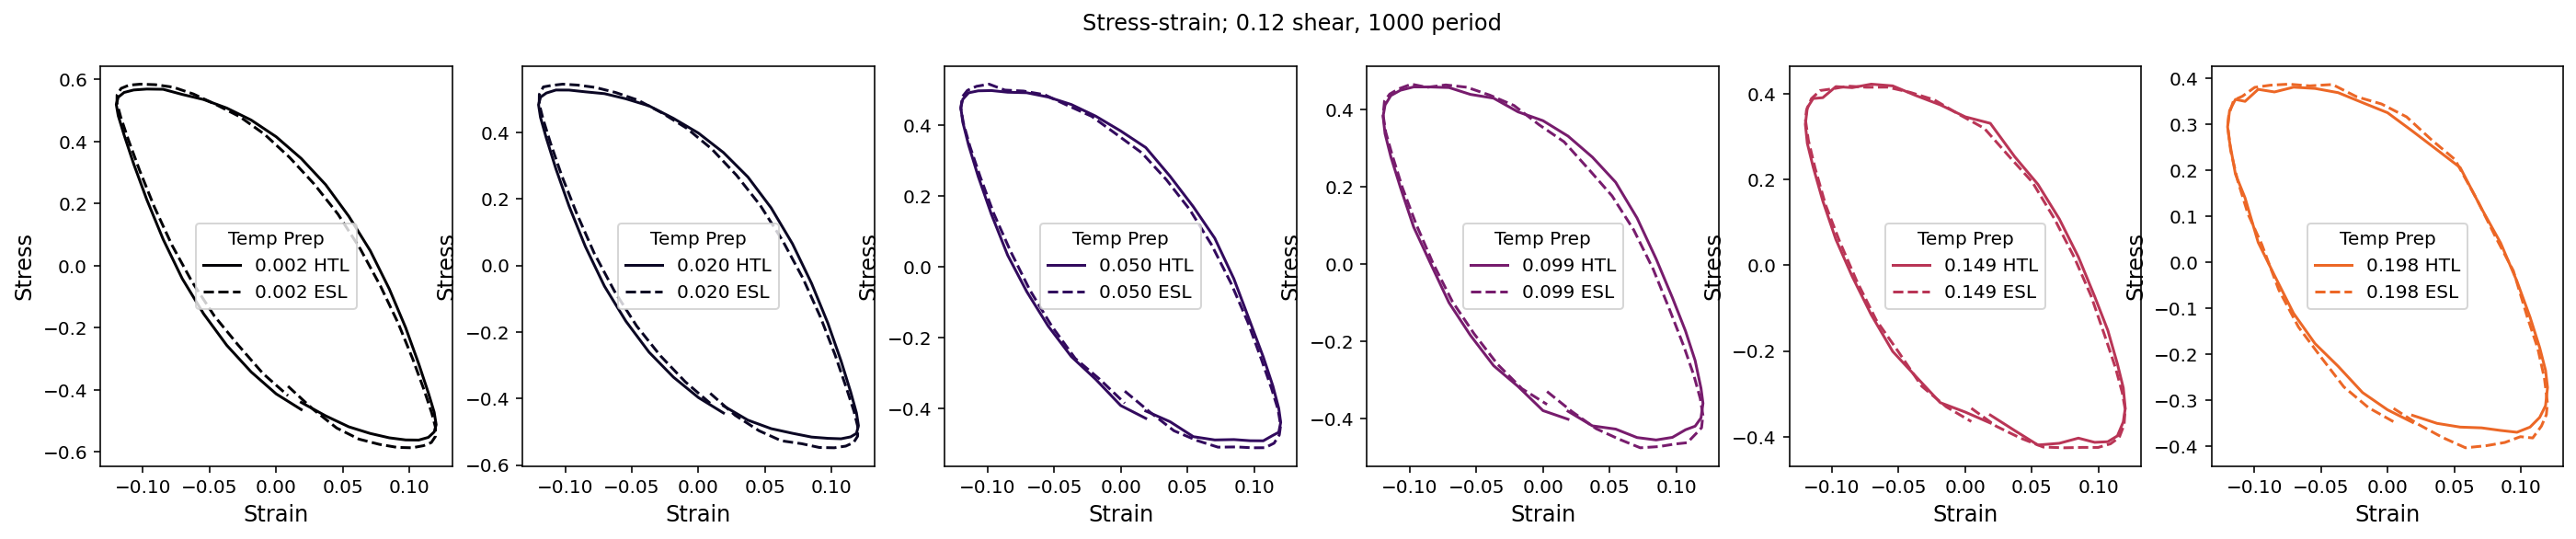

In [36]:
for shear in [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.12]:
    plot_stress_strain(shear, legend=True)

In [37]:
import numpy, scipy.optimize

def fit_sin(tt, yy):
    '''Fit sin to the input time sequence, and return fitting parameters "amp", "omega", "phase", "offset", "freq", "period" and "fitfunc"'''
    tt = numpy.array(tt)
    yy = numpy.array(yy)
    ff = numpy.fft.fftfreq(len(tt), (tt[1]-tt[0]))   # assume uniform spacing
    Fyy = abs(numpy.fft.fft(yy))
    guess_freq = abs(ff[numpy.argmax(Fyy[1:])+1])   # excluding the zero frequency "peak", which is related to offset
    guess_amp = numpy.std(yy) * 2.**0.5
    guess_offset = numpy.mean(yy)
    guess = numpy.array([guess_amp, 2.*numpy.pi*guess_freq, 0., guess_offset])

    def sinfunc(t, A, w, p, c):  return A * numpy.sin(w*t + p) + c
    popt, pcov = scipy.optimize.curve_fit(sinfunc, tt, yy, p0=guess)
    A, w, p, c = popt
    f = w/(2.*numpy.pi)
    fitfunc = lambda t: A * numpy.sin(w*t + p) + c
    return {"amp": A, "omega": w, "phase": p, "offset": c, "freq": f, "period": 1./f, "fitfunc": fitfunc, "maxcov": numpy.max(pcov), "rawres": (guess,popt,pcov)}

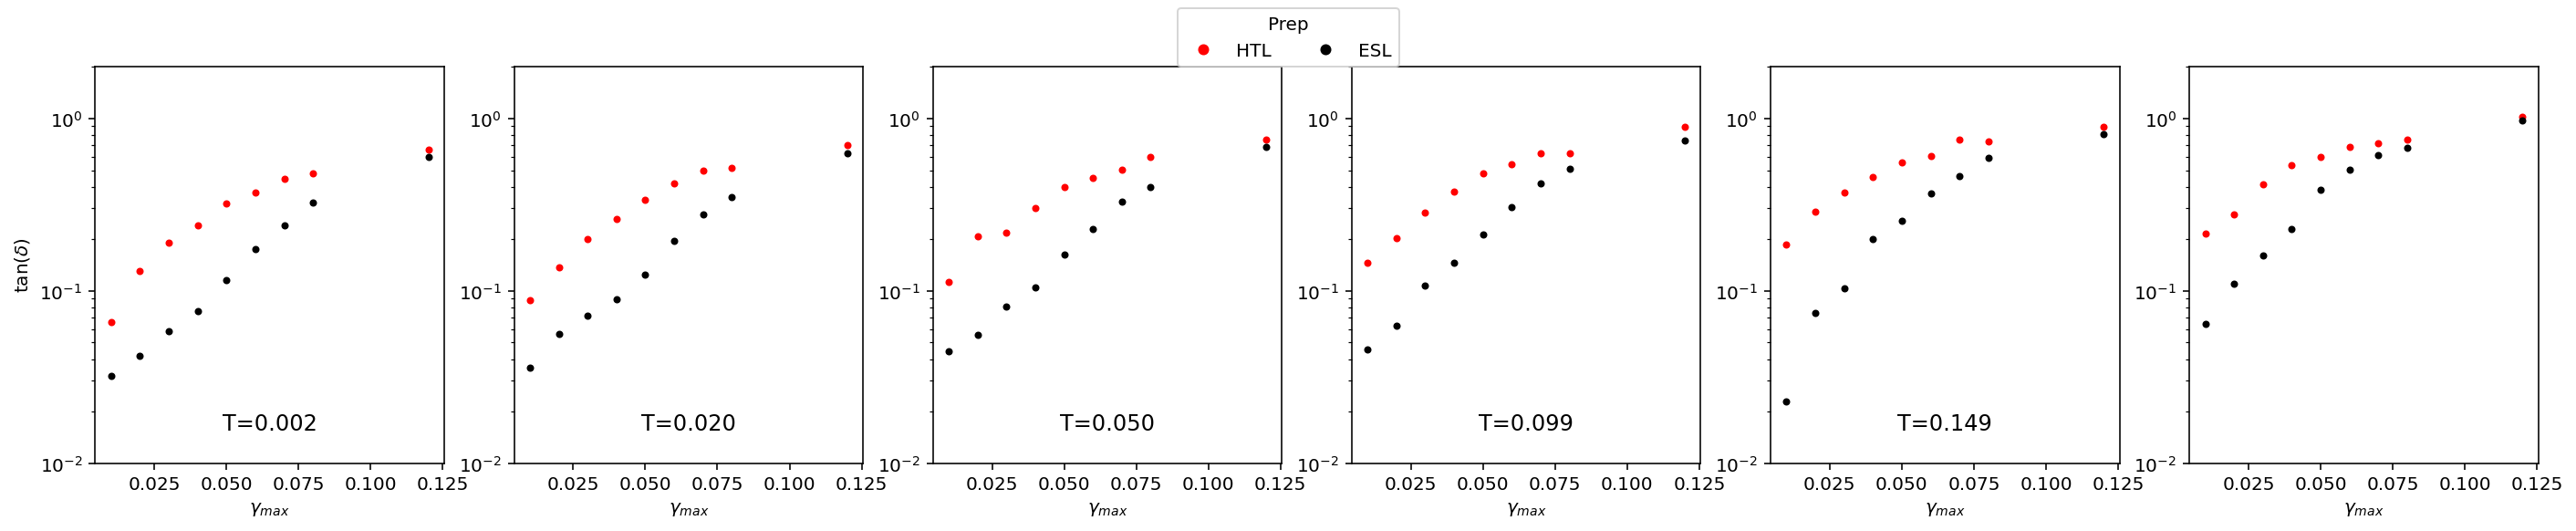

In [41]:
fig, axs = plt.subplots(1, 6, figsize=(24, 4))

cmap = cm.inferno
norm = colors.Normalize(vmin=0, vmax=.3)

for k, v in output.items():

    temps = [0.0019836, 0.019836, 0.049591, 0.099182, 0.14877, 0.19836]
    i = temps.index(k.temp)
    # print(k, len(v))

    stress = np.mean([v_i["stress"].values for v_i in v], axis=0)[:40*5+1]
    strain = np.mean([v_i["strain"].values for v_i in v], axis=0)[:40*5+1]
    stress = np.array([np.mean(stress[i::40]) for i in range(41)])
    strain = np.array([np.mean(strain[i::40]) for i in range(41)])

    tt = np.arange(len(strain))

    # plt.plot(-stress)
    # plt.plot(strain)

    res = fit_sin(tt, -stress)
    # plt.plot(tt, res["fitfunc"](tt), "r-", label="y fit curve", linewidth=2)

    phase0 = res["phase"]

    res = fit_sin(tt, strain)
    # plt.plot(tt, res["fitfunc"](tt), "b-", label="y fit curve", linewidth=2)

    phase1 = res["phase"]


    phase_diff = phase0 - phase1

    tan_delta = np.tan(phase_diff)
    # print(tan_delta)

    if k.prep == "ESL":
        c = "k"
    else:
        c = "r"


    # break
    ax = axs[i]
    ax.plot(k.max_shear, tan_delta, ".", c=c)
for ax in axs:
    ax.set_yscale('log')
    ax.set_ylim(0.01, 2)

handles = [mpl.lines.Line2D([0], [0], marker='.', color='r', linestyle="", markersize=10, label='HTL'),
           mpl.lines.Line2D([0], [0], marker='.', color='k', linestyle="", markersize=10, label='ESL')]

fig.legend(handles=handles, loc='upper center', ncol=2, title="Prep")

for ax in axs:
    ax.set_xlabel(r"$\gamma_{max}$")

axs[0].set_ylabel(r"$\tan(\delta)$")

for i in range(5):
    pos = (0.5, 0.1)
    axs[i].text(*pos, f"T={temps[i]:.3f}", transform=axs[i].transAxes, ha="center", va="center", size="large")

# plt.savefig("tan-delta.png", dpi=300)

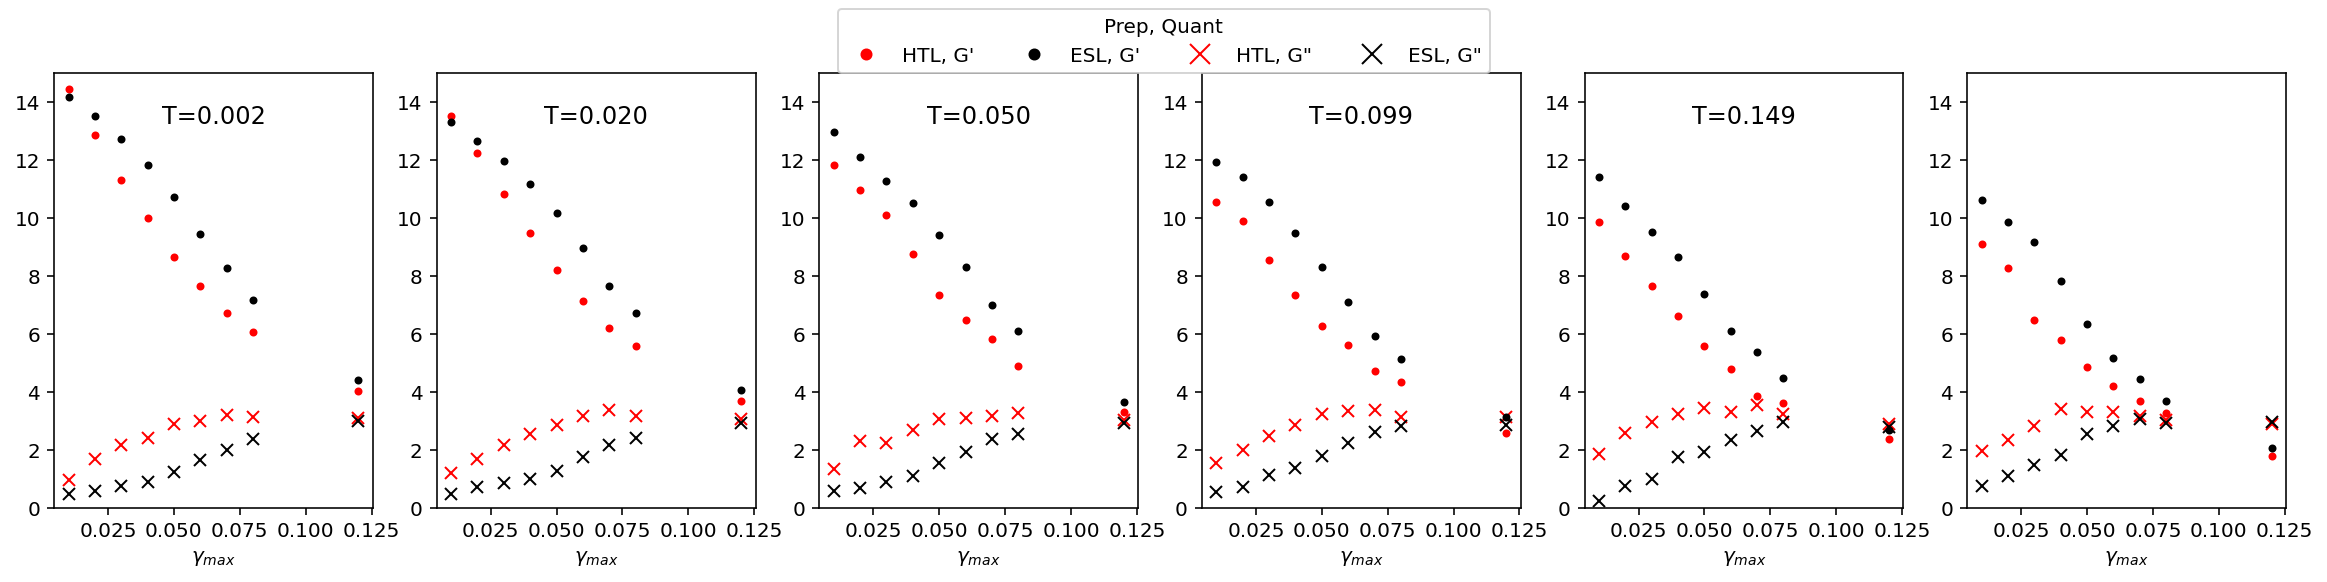

In [43]:
fig, axs = plt.subplots(1, 6, figsize=(20, 4))

cmap = cm.inferno
norm = colors.Normalize(vmin=0, vmax=.3)

for k, v in output.items():

    temps = [0.0019836, 0.019836, 0.049591, 0.099182, 0.14877, 0.19836]
    i = temps.index(k.temp)
    # print(k, len(v))

    stress = np.mean([v_i["stress"].values for v_i in v], axis=0)[:40*5-1]
    strain = np.mean([v_i["strain"].values for v_i in v], axis=0)[:40*5-1]
    stress = np.array([np.mean(stress[i::40]) for i in range(41)])
    strain = np.array([np.mean(strain[i::40]) for i in range(41)])

    tt = np.arange(len(strain))

    # plt.plot(-stress)
    # plt.plot(strain)

    res = fit_sin(tt, -stress)
    # plt.plot(tt, res["fitfunc"](tt), "r-", label="y fit curve", linewidth=2)

    phase0 = res["phase"]
    amp0 = res["amp"]

    res = fit_sin(tt, strain)
    # plt.plot(tt, res["fitfunc"](tt), "b-", label="y fit curve", linewidth=2)

    phase1 = res["phase"]
    amp1 = res["amp"]

    phase_diff = phase0 - phase1
    amp_g = amp0 / amp1

    tan_delta = np.tan(phase_diff)
    # print(tan_delta)

    if k.prep == "ESL":
        c = "k"
    else:
        c = "r"


    # break
    ax = axs[i]
    ax.plot(k.max_shear, amp_g * np.cos(tan_delta), ".", c=c)
    ax.plot(k.max_shear, amp_g * np.sin(tan_delta), "x", c=c)
for ax in axs:
    # ax.set_yscale('log')
    ax.set_ylim(0.0, 15)

handles = [mpl.lines.Line2D([0], [0], marker='.', color='r', linestyle="", markersize=10, label='HTL, G\''),
           mpl.lines.Line2D([0], [0], marker='.', color='k', linestyle="", markersize=10, label='ESL, G\''),
           mpl.lines.Line2D([0], [0], marker='x', color='r', linestyle="", markersize=10, label='HTL, G\"'),
           mpl.lines.Line2D([0], [0], marker='x', color='k', linestyle="", markersize=10, label='ESL, G\"')]

fig.legend(handles=handles, loc='upper center', ncol=4, title="Prep, Quant")

for i in range(5):
    pos = (0.5, 0.9)
    axs[i].text(*pos, f"T={temps[i]:.3f}", transform=axs[i].transAxes, ha="center", va="center", size="large")

for ax in axs:
    ax.set_xlabel(r"$\gamma_{max}$")

plt.savefig("g-prime-g-double-prime.png", dpi=300)

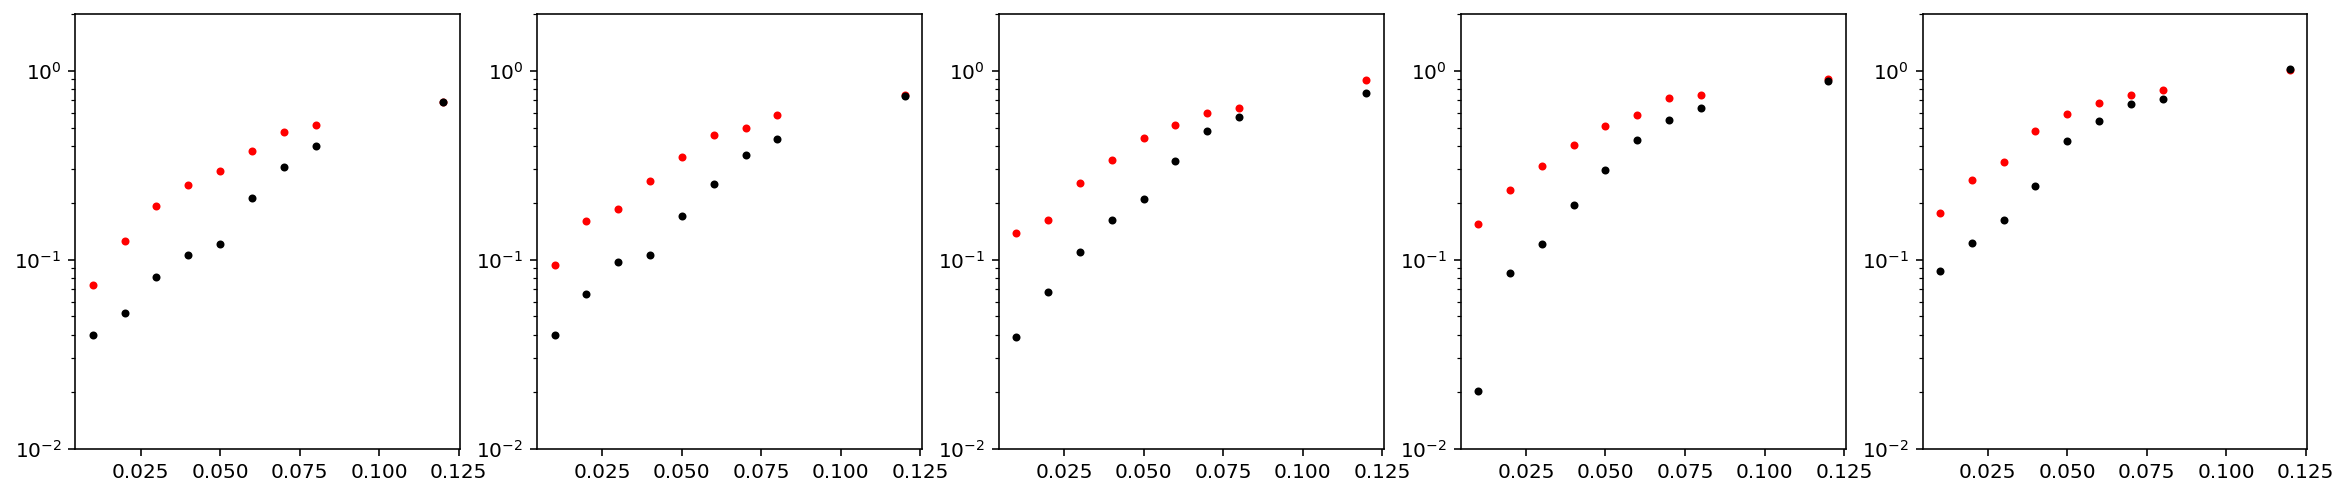

In [57]:
fig, axs = plt.subplots(1, 5, figsize=(20, 4))

cmap = cm.inferno
norm = colors.Normalize(vmin=0, vmax=.3)

for k, v in output.items():

    temps = [0.019836, 0.049591, 0.099182, 0.14877, 0.19836]
    i = temps.index(k.temp)
    # print(k, len(v))

    stress = np.mean([v_i["stress"].values for v_i in v], axis=0)[:40*10]
    strain = np.mean([v_i["strain"].values for v_i in v], axis=0)[:40*10]
    stress = np.array([np.mean(stress[i::40]) for i in range(41)])
    strain = np.array([np.mean(strain[i::40]) for i in range(41)])

    tt = np.arange(len(strain))

    # plt.plot(-stress)
    # plt.plot(strain)

    res = fit_sin(tt, -stress)
    # plt.plot(tt, res["fitfunc"](tt), "r-", label="y fit curve", linewidth=2)

    phase0 = res["phase"]

    res = fit_sin(tt, strain)
    # plt.plot(tt, res["fitfunc"](tt), "b-", label="y fit curve", linewidth=2)

    phase1 = res["phase"]

    phase_diff = phase0 - phase1

    tan_delta = np.tan(phase_diff)
    # print(tan_delta)

    if k.prep == "ESL":
        c = "k"
    else:
        c = "r"


    # break
    ax = axs[i]
    ax.plot(k.max_shear, tan_delta, ".", c=c)
for ax in axs:
    ax.set_yscale('log')
    ax.set_ylim(0.01, 2)

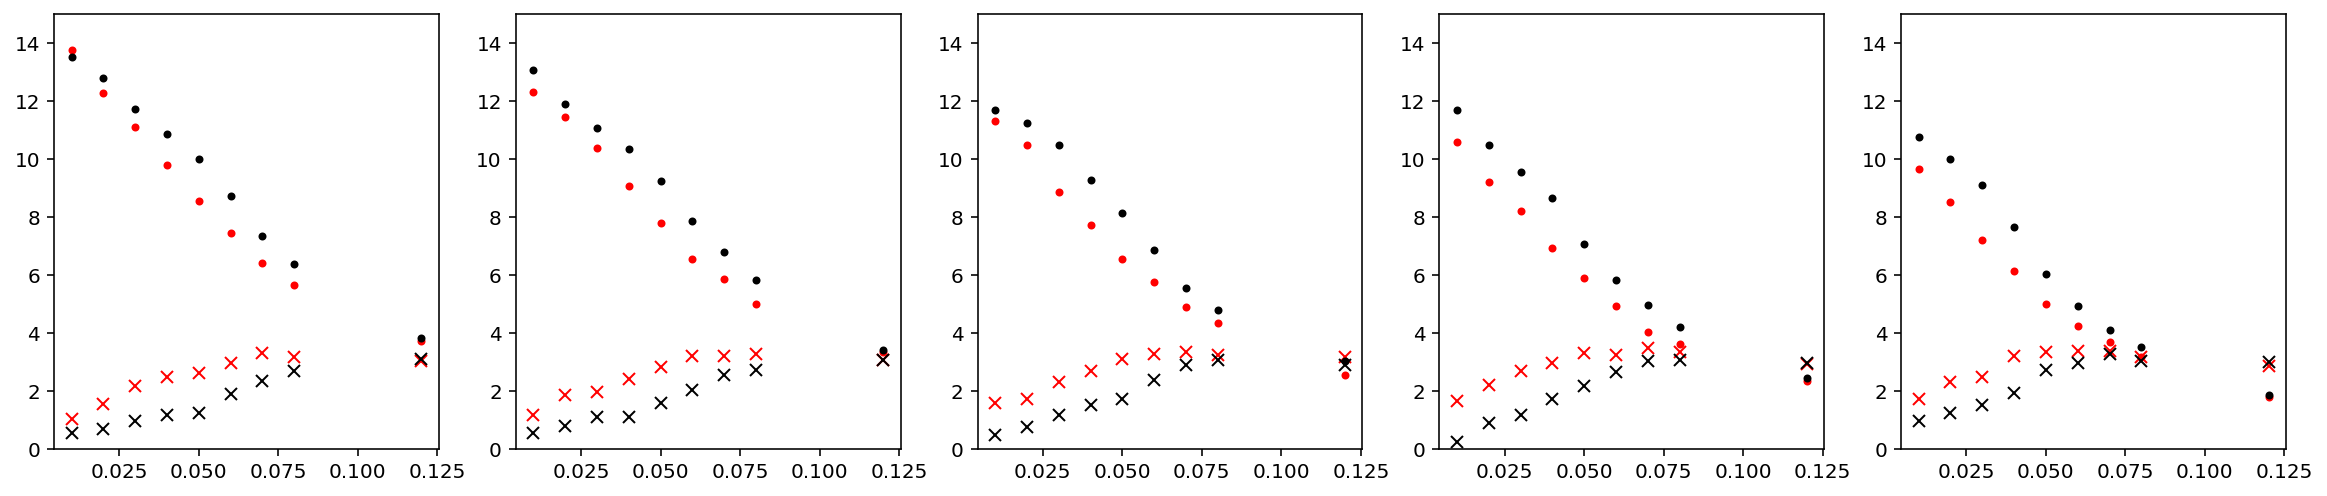

In [58]:
fig, axs = plt.subplots(1, 5, figsize=(20, 4))

cmap = cm.inferno
norm = colors.Normalize(vmin=0, vmax=.3)

for k, v in output.items():

    temps = [0.019836, 0.049591, 0.099182, 0.14877, 0.19836]
    i = temps.index(k.temp)
    # print(k, len(v))

    stress = np.mean([v_i["stress"].values for v_i in v], axis=0)[:40*10]
    strain = np.mean([v_i["strain"].values for v_i in v], axis=0)[:40*10]
    stress = np.array([np.mean(stress[i::40]) for i in range(41)])
    strain = np.array([np.mean(strain[i::40]) for i in range(41)])

    tt = np.arange(len(strain))

    # plt.plot(-stress)
    # plt.plot(strain)

    res = fit_sin(tt, -stress)
    # plt.plot(tt, res["fitfunc"](tt), "r-", label="y fit curve", linewidth=2)

    phase0 = res["phase"]
    amp0 = res["amp"]

    res = fit_sin(tt, strain)
    # plt.plot(tt, res["fitfunc"](tt), "b-", label="y fit curve", linewidth=2)

    phase1 = res["phase"]
    amp1 = res["amp"]

    phase_diff = phase0 - phase1
    amp_g = amp0 / amp1

    tan_delta = np.tan(phase_diff)
    # print(tan_delta)

    if k.prep == "ESL":
        c = "k"
    else:
        c = "r"


    # break
    ax = axs[i]
    ax.plot(k.max_shear, amp_g * np.cos(tan_delta), ".", c=c)
    ax.plot(k.max_shear, amp_g * np.sin(tan_delta), "x", c=c)
for ax in axs:
    # ax.set_yscale('log')
    ax.set_ylim(0.0, 15)

In [30]:
def plot_stress_strain_transient(shear, axs=None, legend=True):
    if axs is None:
        fig, axs = plt.subplots(1, 5, figsize=(20, 4))
    else:
        fig = axs.figure
    
    cmap = cm.inferno
    norm = colors.Normalize(vmin=0, vmax=.3)

    for k, v in output.items():
        if k.max_shear != shear:
            continue
        # print(k)
        c = cmap(norm(k.temp))
        if k.prep == "ESL":
            ls = "--"
        else:
            ls = ":"

        # temp to idx mapping using
        temps = [0.019836, 0.049591, 0.099182, 0.14877, 0.19836]
        i = temps.index(k.temp)

        stress = np.mean([v_i["stress"].values for v_i in v], axis=0)[:40*5]
        strain = np.mean([v_i["strain"].values for v_i in v], axis=0)[:40*5]
        # frames = v[0]["frame"].values
        axs[i].plot(strain, stress, color=c, linestyle=ls, label=f"{k.temp:.3f} {k.prep}", alpha=1)
    for ax in axs:
        ax.set_ylabel("Stress", size="large")
        ax.set_xlabel("Strain", size="large")
        if legend:
            ax.legend(title="Temp Prep")
    fig.suptitle(f"Stress-strain; {shear} shear, 1000 period")

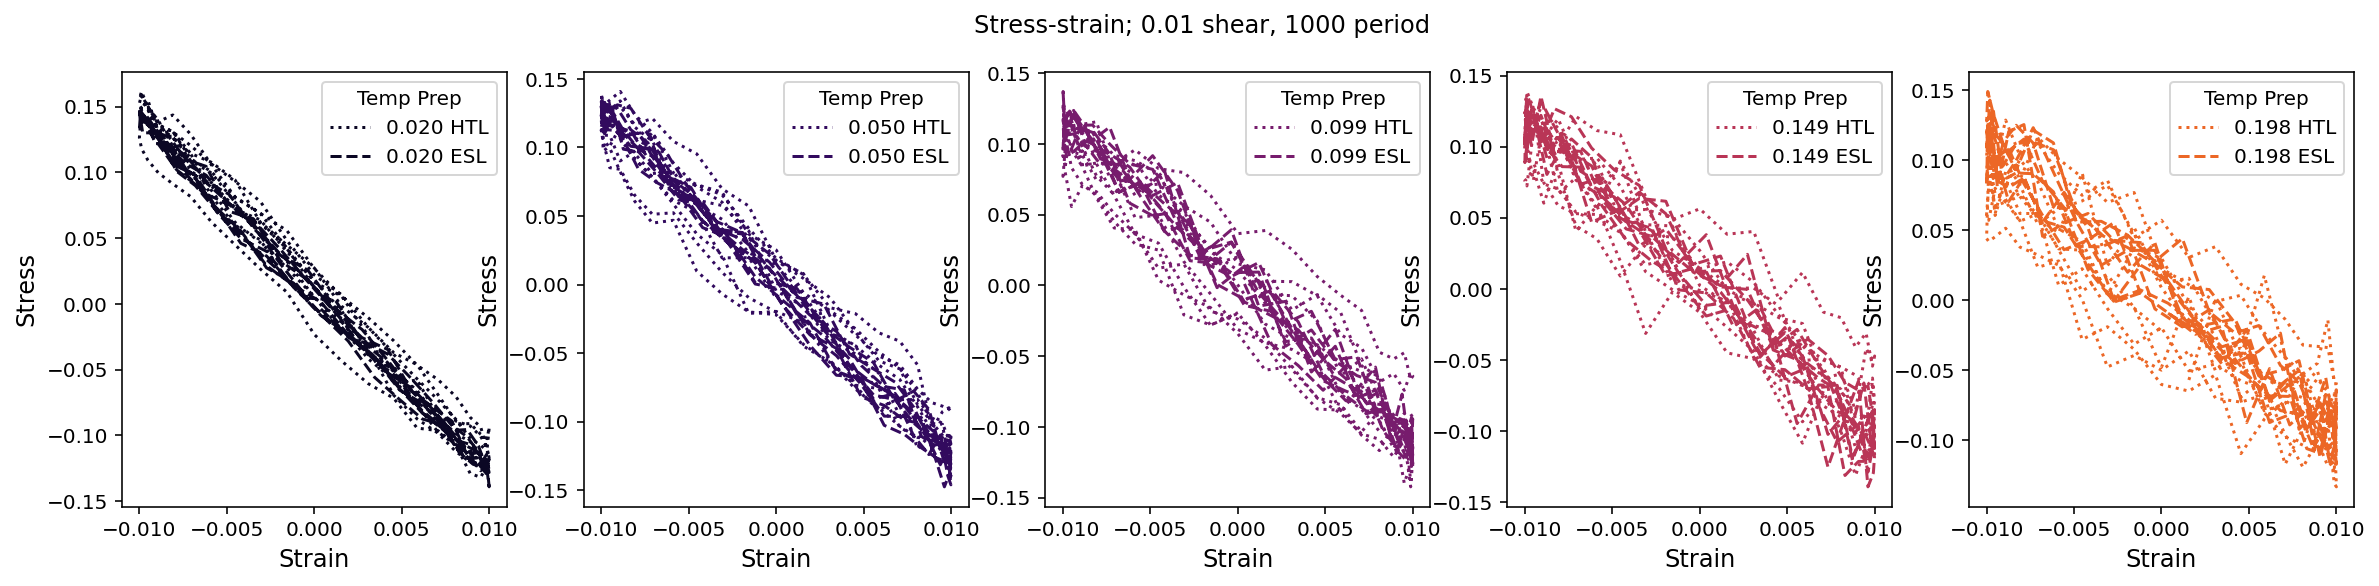

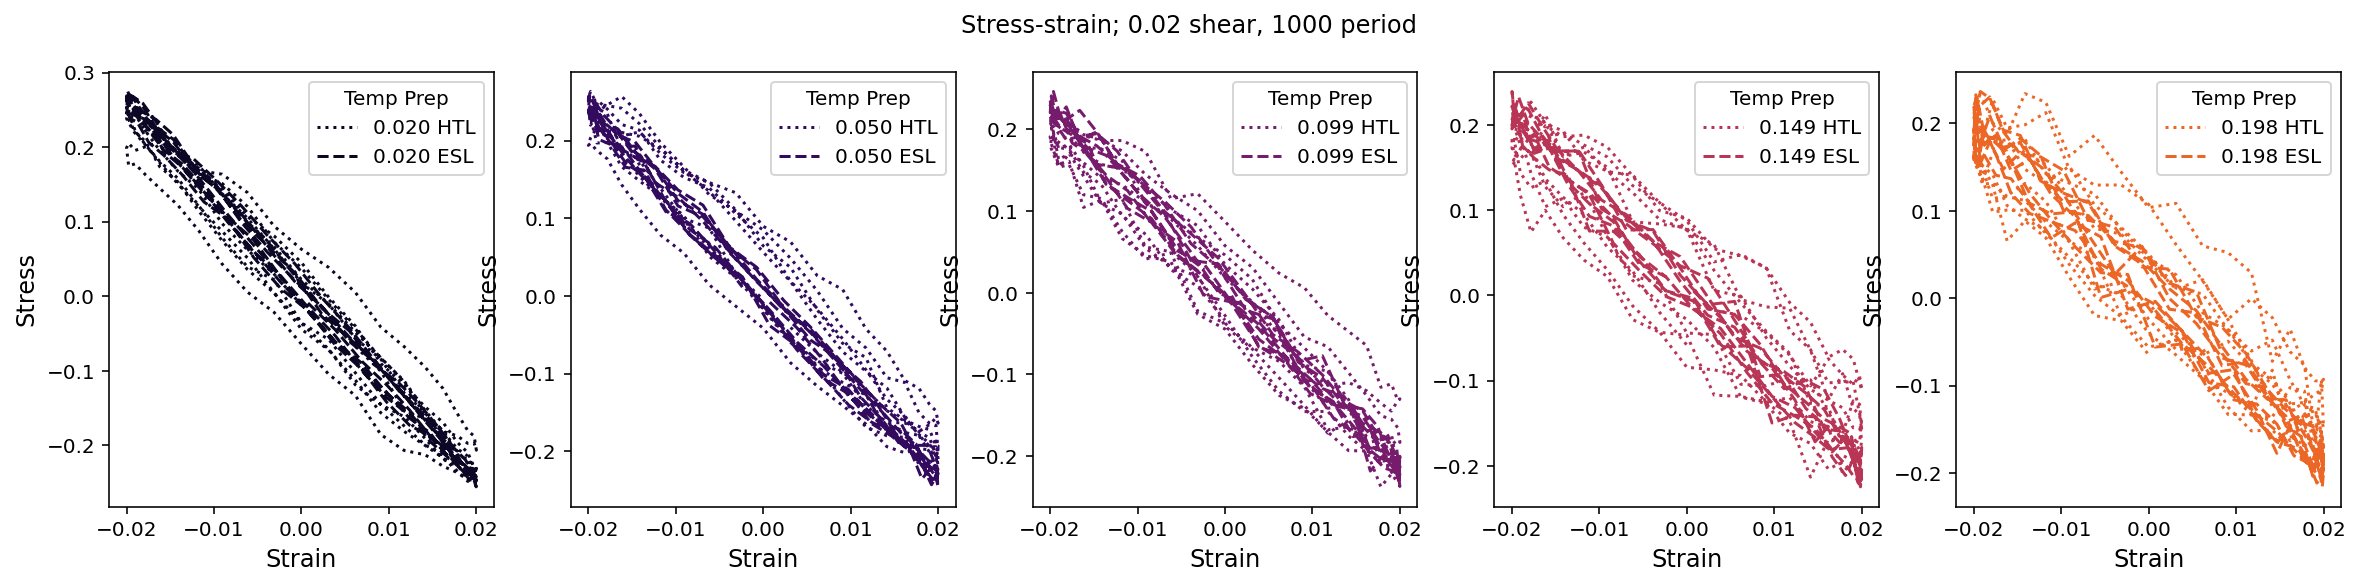

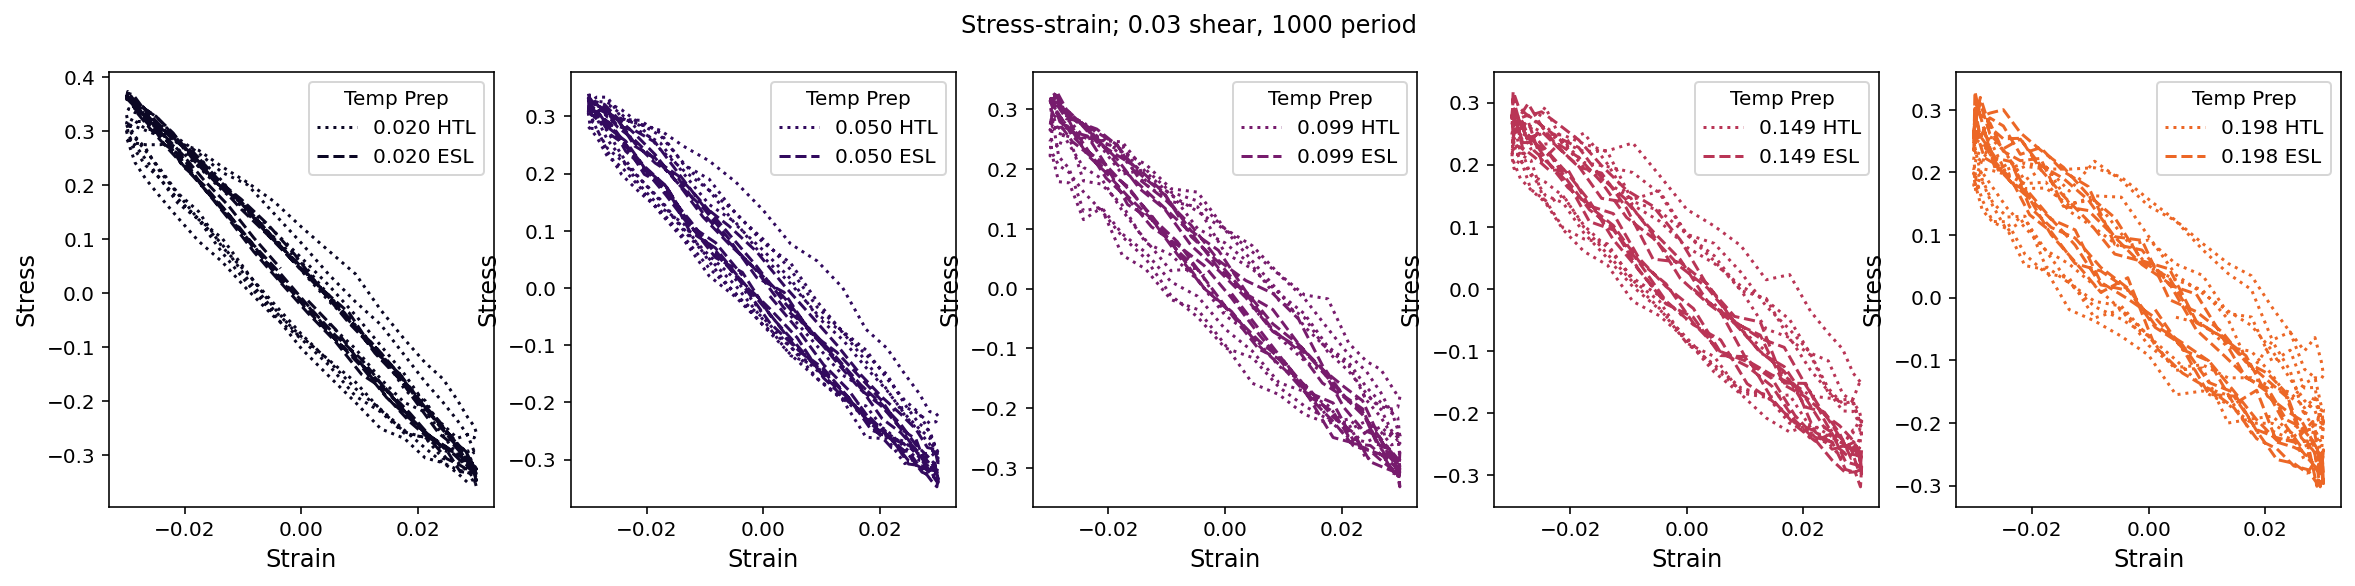

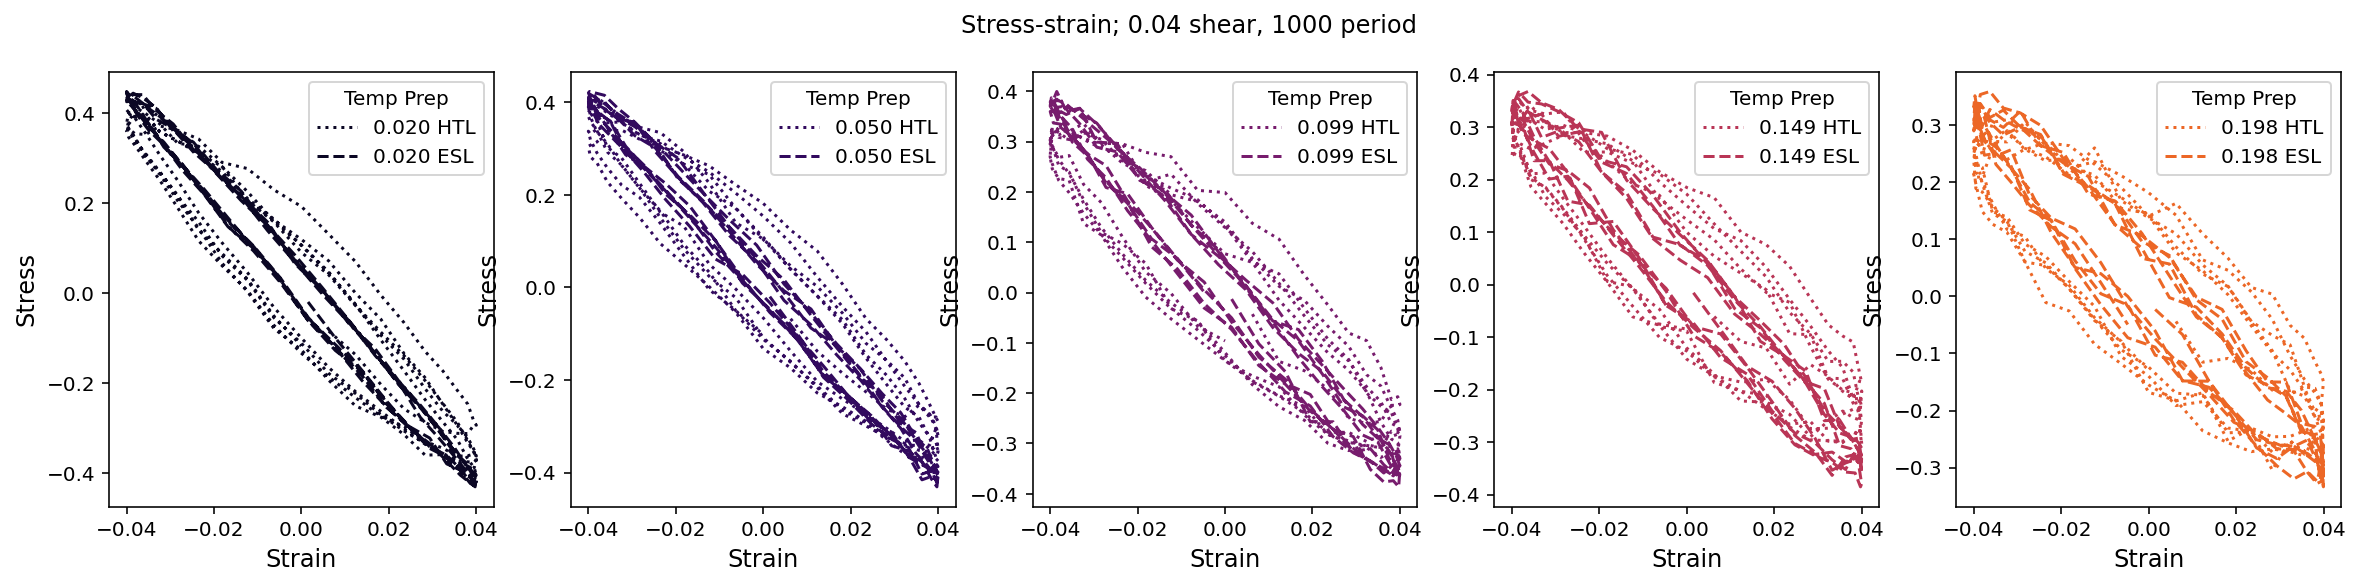

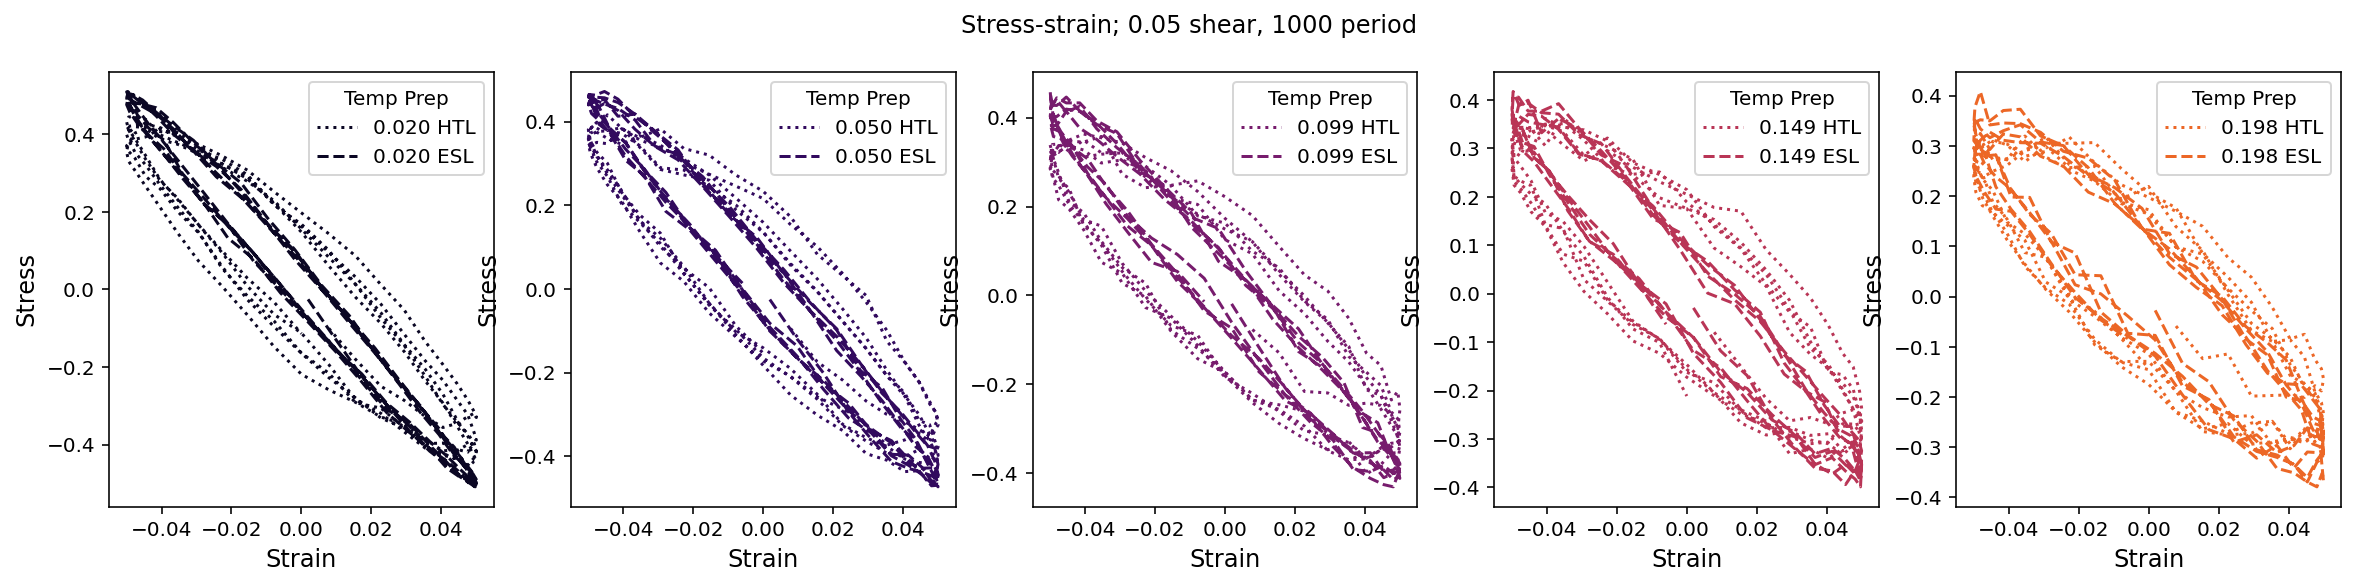

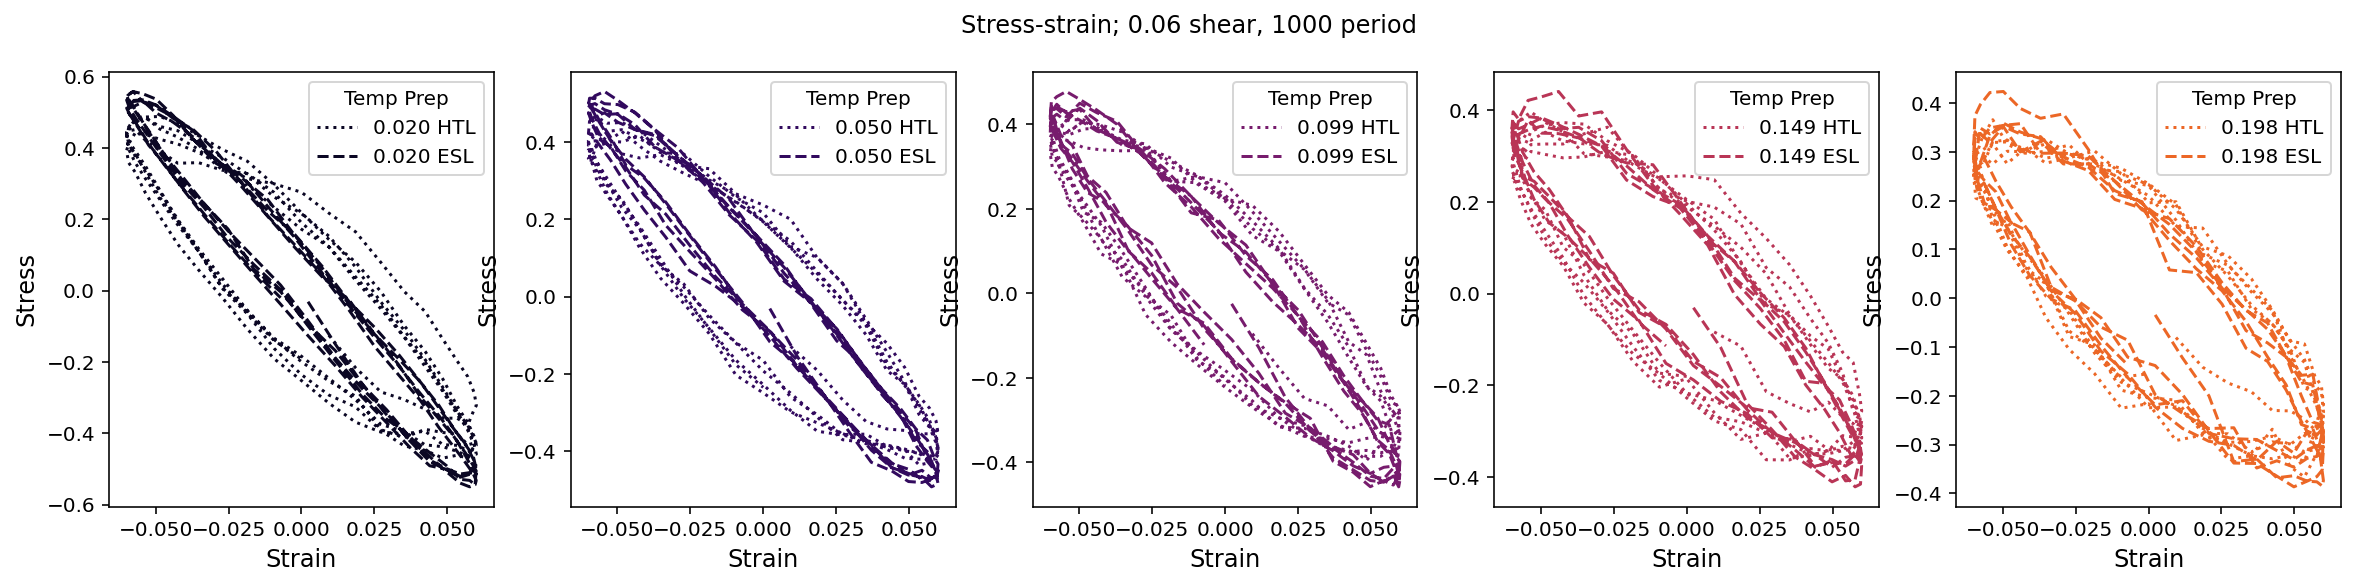

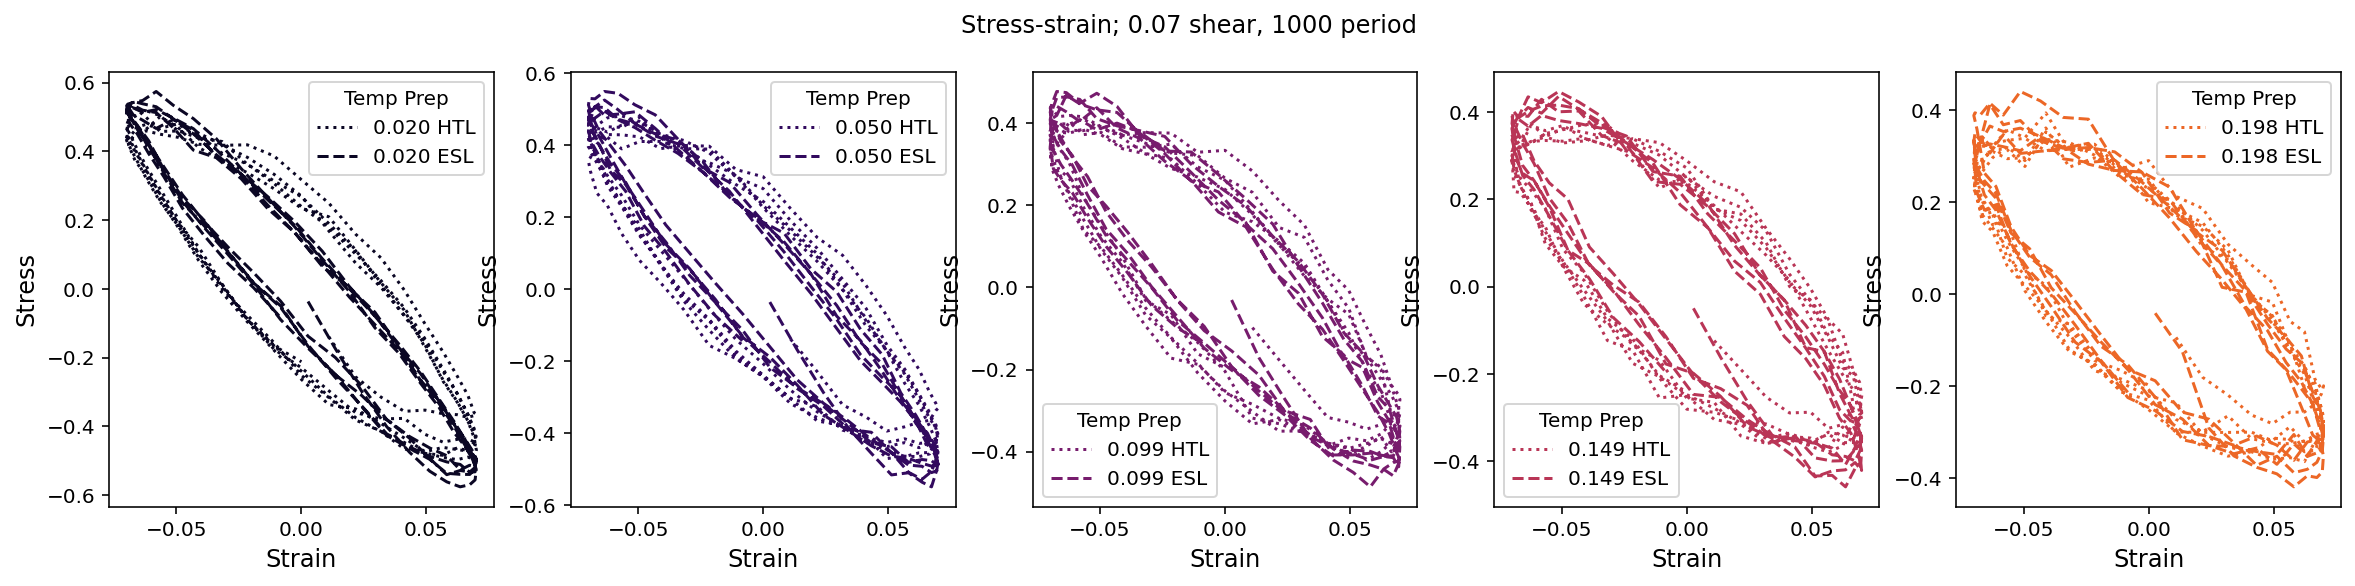

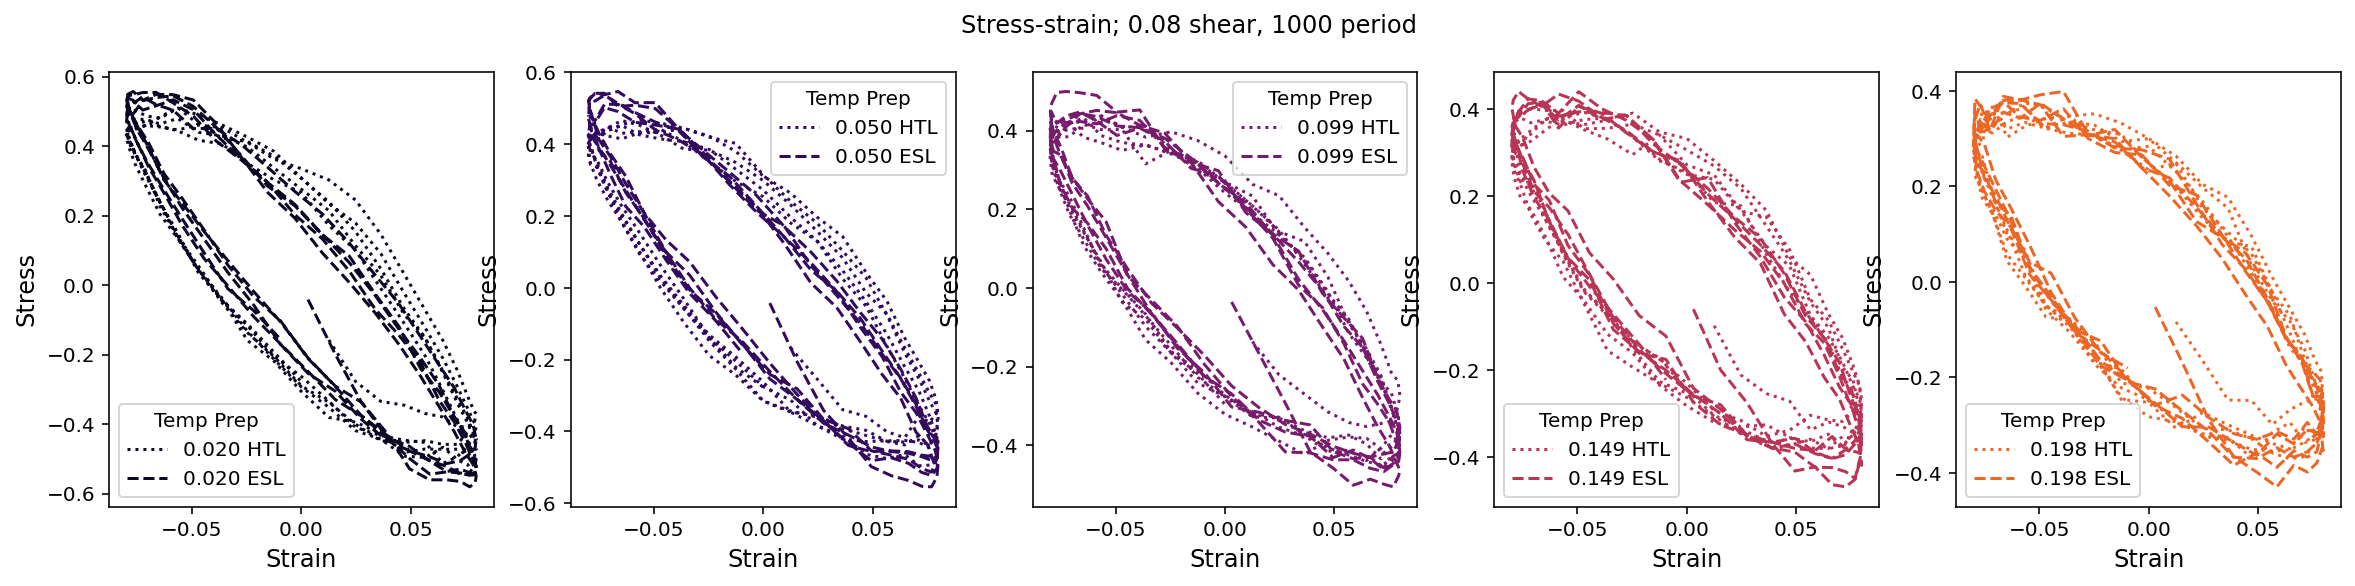

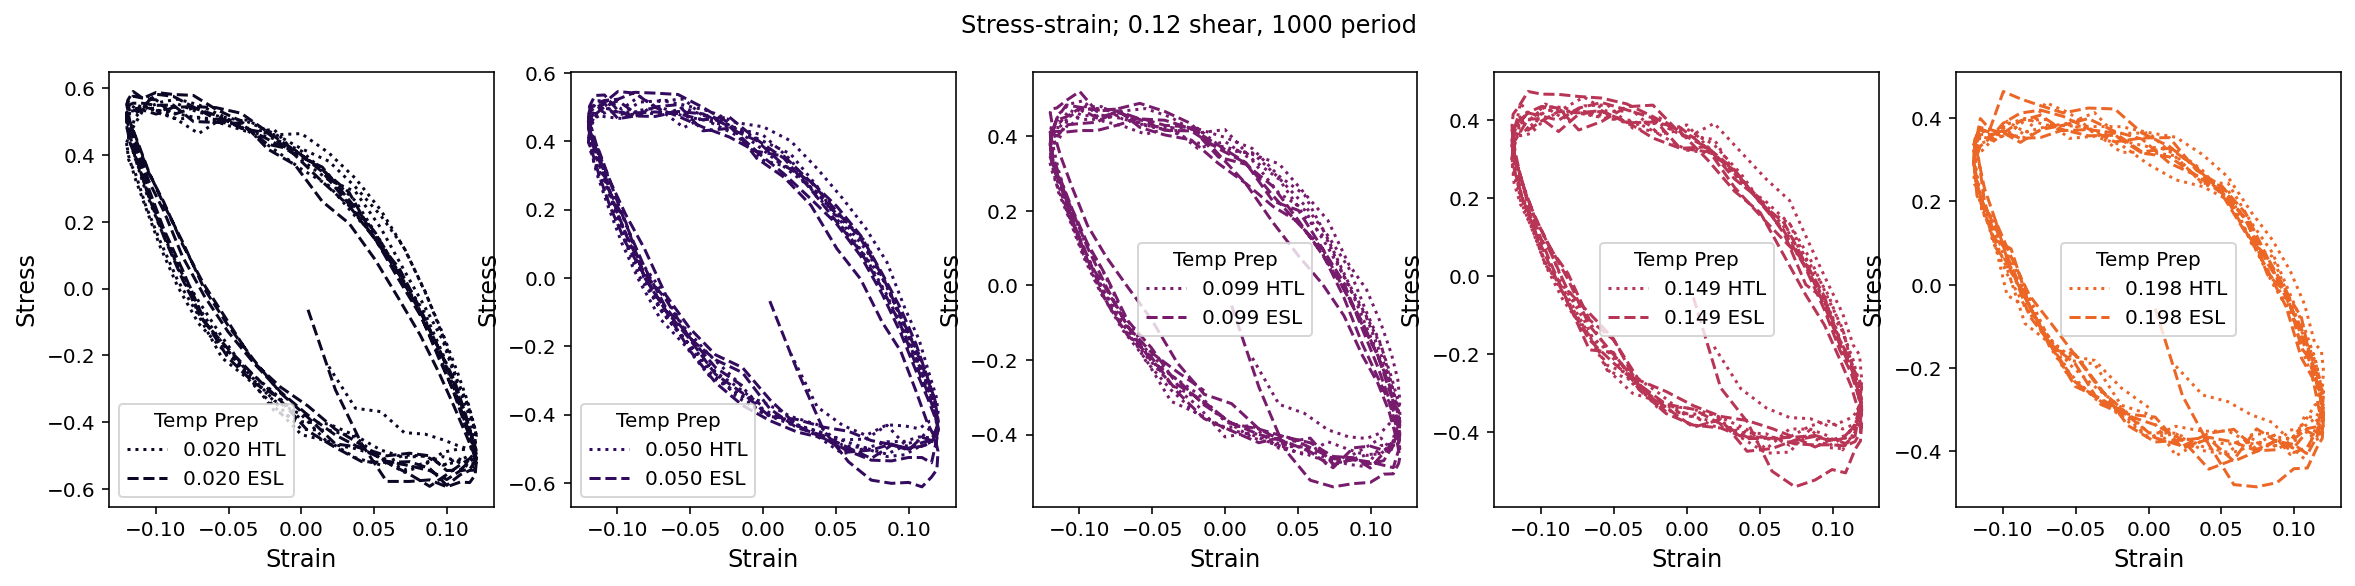

In [31]:
for shear in [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.12]:
    plot_stress_strain_transient(shear, legend=True)